# $V$ closure test with HERA $xF_3^{\gamma Z}$ kinematics

The fitted PDF is

$$V(x,Q_0)=\sum_q\left[q(x,Q_0)-\bar q(x,Q_0)\right],$$

represented through $xV$ on the evolved FK grid (evolution-basis PID 200). By default, PDF combinations other than $V$ are held fixed to their NNPDF reference prediction, and pseudo-data are drawn from

$$y_i^{\rm pseudo}\sim\mathcal N\!\left(b_i+v(c_{\rm true};Q_i^2)\left([W_{\rm sub}(xV^{\rm ref})]_i+t_i^{\rm fixed}\right),\Sigma\right),$$

or

$$y_i^{\rm pseudo}\sim\mathcal N\!\left(v(c_{\rm true};Q_i^2)\left([W_{\rm sub}(xV^{\rm ref})]_i+b_i+t_i^{\rm fixed}\right),\Sigma\right),$$

where $b_i$ contains the non-$V$ channels and $t_i^{\rm fixed}$ is the PID-200 contribution from FK nodes outside the fitted $x$ range.

The real HERA central values remain available as `D_real`. The `data_mode` and background choices are isolated in Section 2 so they can be changed later.

## Outline
1. Load and inspect the HERA inputs
2. Configure the background, EFT model, and pseudo-data
3. Inspect the reference $V$
4. Construct the B-spline design matrix
5. Separate, joint, and one-step fits
6. Compare the fitted PDF and predictions with pseudo-data
7. Simulation Study

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import lhapdf

from scipy.integrate import quad
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm

from utils import (
    bspline_basis,
    klin, kquad, v_c, v_prime_c, v_second_c,
    build_K_matrix, build_K_prime_matrix,
    fit_beta_c, mle_beta, mle_c, one_step_c,
    one_step_confidence_interval, bootstrap_confidence_interval,
    joint_mle_asymptotic_confidence_interval,
    joint_mle_analytical_hessian, joint_mle_numerical_hessian,
    plot_by_Q2,
    setup_experiment, run_single_experiment,
)

---
## 1. Load the HERA data and FK matrices

`D_real` contains the measured central values. `W` is the PID-200 $V$ matrix, including the conversion from the Yadism `F3_total` normalization to measured $xF_3^{\gamma Z}$. It multiplies $xV$ on `grid`; every other FK channel is included in the saved fixed offset.

Set `data_information_multiplier` to 2 or 3 to study twice or three times the information without duplicating kinematic rows. In another word, it keeps the original 67 points and uses the covariance of the average of $R$ independent datasets, $\Sigma_{\rm eff}=\Sigma/R$.

In [60]:
archive = np.load("Dataset/data_HERA_F3_aZ_PID200.npz")

# Effective-information study: 1 is the original covariance; 2 or 3
# represents the average of 2 or 3 independent datasets.
data_information_multiplier = 100
if isinstance(data_information_multiplier, bool) or not isinstance(data_information_multiplier, (int, np.integer)):
    raise TypeError("data_information_multiplier must be a positive integer")
if data_information_multiplier < 1:
    raise ValueError("data_information_multiplier must be at least 1")

R = data_information_multiplier
error_scale = 1 / np.sqrt(R)

Q0 = float(archive["Q0"])
grid_full = archive["grid"]
W_full = archive["W"]
channel_pids = archive["channel_pids"]
xQ2 = archive["kinematics"]
D_real = archive["data"]
Sigma = archive["Sigma"] / R
errors = archive["errors"] * error_scale
stat_errors = archive["stat_errors"] * error_scale
sys_errors = archive["sys_errors"] * error_scale
prediction_reference = archive["prediction"]
prediction_rest_reference = archive["prediction_rest"]
target_pid = int(archive["target_pid"])
if target_pid != 200:
    raise ValueError(f"V_demo requires PID 200, but the archive contains PID {target_pid}")
xv_full_reference = archive["target_xpdf_grid"]
v_full_reference = archive["target_pdf_grid"]

# Fit only FK nodes inside the measured x range. PID-200 nodes outside
# this range stay fixed to NNPDF, but remain inside the EFT factor.
restrict_to_data_x_range = True
if restrict_to_data_x_range:
    grid_mask = (grid_full >= xQ2[:, 0].min()) & (grid_full <= xQ2[:, 0].max())
else:
    grid_mask = np.ones(len(grid_full), dtype=bool)

grid = grid_full[grid_mask]
W = W_full[:, grid_mask]
W_all = archive["W_all"][:, :, grid_mask]
xv_reference = xv_full_reference[grid_mask]
v_reference = v_full_reference[grid_mask]
target_offset = W_full[:, ~grid_mask] @ xv_full_reference[~grid_mask]
prediction_v_reference = W @ xv_reference + target_offset

print(f"Information multiplier = {R}; N_data = {len(D_real)}")
print(f"Effective standard-error scale = 1/sqrt({R}) = {1 / np.sqrt(R):.6g}")
print(f"Fitted grid nodes = {len(grid)}/{len(grid_full)}, Q0 = {Q0:g} GeV")
print(f"W: {W.shape}; W_all: {W_all.shape}")
print(f"x range: [{xQ2[:, 0].min():.4g}, {xQ2[:, 0].max():.4g}]")
print(f"Q² range: [{xQ2[:, 1].min():.0f}, {xQ2[:, 1].max():.0f}] GeV²")
print("Evolution-basis channels:", channel_pids.tolist())
assert np.allclose(prediction_v_reference, archive["prediction_target"])
assert np.allclose(prediction_rest_reference + prediction_v_reference, prediction_reference)
assert np.allclose(Sigma, archive["Sigma"] / R)

Information multiplier = 100; N_data = 67
Effective standard-error scale = 1/sqrt(100) = 0.1
Fitted grid nodes = 17/30, Q0 = 1.65 GeV
W: (67, 17); W_all: (67, 9, 17)
x range: [0.013, 0.65]
Q² range: [1000, 30000] GeV²
Evolution-basis channels: [21, 103, 108, 115, 100, 203, 208, 215, 200]


In [ ]:
save_fig = True

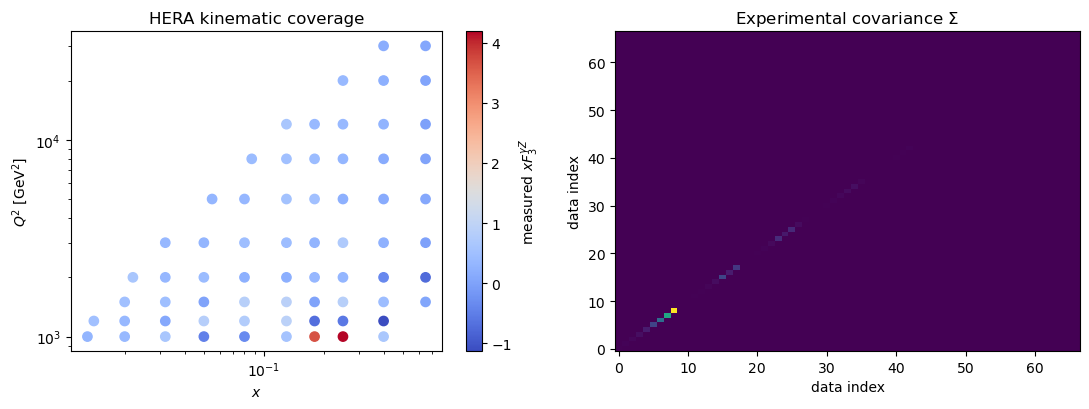

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sc = axes[0].scatter(xQ2[:, 0], xQ2[:, 1], c=D_real, cmap="coolwarm", s=45)
axes[0].set(xscale="log", yscale="log", xlabel="$x$", ylabel="$Q^2$ [GeV$^2$]", title="HERA kinematic coverage")
fig.colorbar(sc, ax=axes[0], label=r"measured $xF_3^{\gamma Z}$")

axes[1].imshow(Sigma, origin="lower", aspect="auto", cmap="viridis")
axes[1].set(xlabel="data index", ylabel="data index", title="Experimental covariance $\Sigma$")
plt.tight_layout()
plt.show()

Figure saved at: ../results/HERA/HERA_BCDMS_kinematic_coverage.pdf


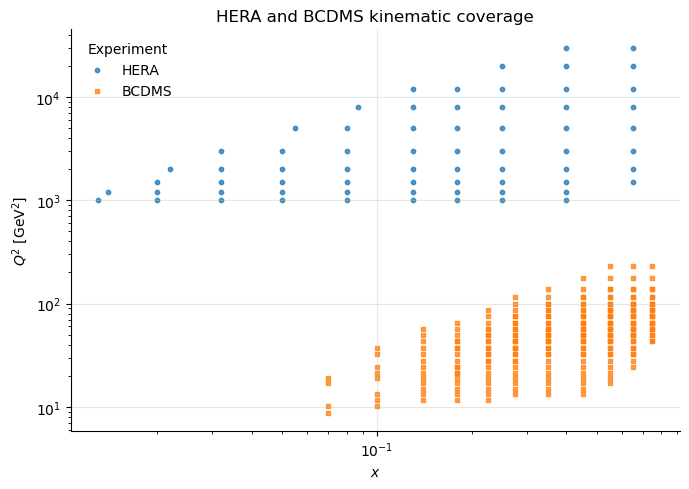

In [4]:
# Combined coverage of the HERA and BCDMS datasets used in these demos.
# This cell can run independently of the fitting and LHAPDF cells.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

coverage_datasets = {
    "HERA": ("Dataset/data_HERA_F3_aZ_PID200.npz", "C0", "o"),
    "BCDMS": ("Dataset/data_208.npz", "C1", "s"),
}
save_coverage_fig = True
coverage_output = Path("../results/HERA/HERA_BCDMS_kinematic_coverage.pdf")

fig, ax = plt.subplots(figsize=(7, 5))
for experiment, (archive_path, color, marker) in coverage_datasets.items():
    with np.load(archive_path) as coverage_archive:
        coverage_points = coverage_archive["kinematics"]
    ax.scatter(
        coverage_points[:, 0], coverage_points[:, 1],
        s=10, color=color, marker=marker, alpha=0.75, label=experiment,
    )

ax.set(
    xscale="log", yscale="log", xlabel=r"$x$",
    ylabel=r"$Q^2$ [GeV$^2$]", title="HERA and BCDMS kinematic coverage",
)
ax.legend(title="Experiment", frameon=False)
ax.grid(True, which="major", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

if save_coverage_fig:
    coverage_output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(coverage_output, bbox_inches="tight")
    print("Figure saved at:", coverage_output)
plt.show()


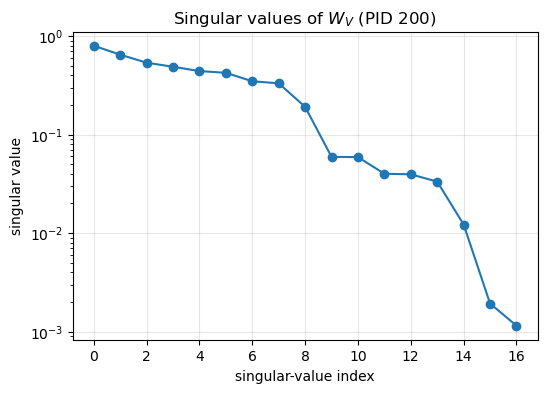

In [5]:
singular_values = np.linalg.svd(W, compute_uv=False)
plt.figure(figsize=(6, 4))
plt.semilogy(singular_values, "o-")
plt.xlabel("singular-value index")
plt.ylabel("singular value")
plt.title(r"Singular values of $W_V$ (PID 200)")
plt.grid(alpha=0.3)
plt.show()

---
## 2. Background and EFT configuration

`background_mode` controls the non-$V$ contribution:

- `"fixed_nnpdf"` (default): use the saved NNPDF contribution from all other channels;
- `"none"`: treat the measurement as if it were purely $V$;
- `"custom"`: supply a length-67 array in `custom_background`.

`background_inside_eft` controls where the selected background enters. If it is `False`, the model is `background + v(c) * (A @ beta + target_offset)`. If it is `True`, the model is `v(c) * (A @ beta + target_offset + background)`. The out-of-range PID-200 contribution `target_offset` always remains inside the EFT factor.

In [62]:
background_mode = "fixed_nnpdf"  # "fixed_nnpdf", "none", or "custom"
custom_background = None
background_inside_eft = True  # set True to multiply the background by v(c)

if background_mode == "fixed_nnpdf":
    background = prediction_rest_reference.copy()
elif background_mode == "none":
    background = np.zeros_like(D_real)
elif background_mode == "custom":
    
    if custom_background is None:
        raise ValueError("Set custom_background to an array with the same shape as D_real")
    background = np.asarray(custom_background, dtype=float)
    if background.shape != D_real.shape:
        raise ValueError(f"custom_background has shape {background.shape}; expected {D_real.shape}")
else:
    raise ValueError(f"Unknown background_mode: {background_mode!r}")

# Split the fixed prediction into the part subtracted before fitting and
# the part multiplied by the EFT factor. This keeps all downstream fits
# in the form D_fit = v(c) * (A @ beta + eft_fixed_offset) + noise.
if background_inside_eft:
    additive_background = np.zeros_like(background)
    eft_background = background.copy()
else:
    additive_background = background.copy()
    eft_background = np.zeros_like(background)
eft_fixed_offset = target_offset + eft_background

print("background mode:", background_mode)
print("background inside EFT:", background_inside_eft)

background mode: fixed_nnpdf
background inside EFT: True


saved figure at: ../results/HERA/EFT_kernel_Lambda=500.pdf


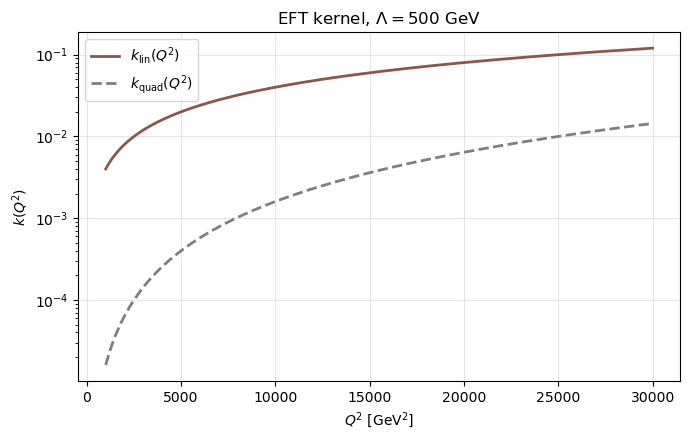

In [30]:
# EFT factor v(c,Q²) = 1 + (Q²/Lambda²)c + (Q⁴/Lambda⁴)c².
Lambda = 500.0
_klin = lambda z: klin(z, Lambda=Lambda)
_kquad = lambda z: kquad(z, Lambda=Lambda)
#_kquad = lambda z, **kwargs: np.zeros_like(np.asarray(z, dtype=float))
_v_c = lambda c, xQ2: v_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_second_c = lambda c, xQ2: v_second_c(c, xQ2, kquad=_kquad)

assert np.allclose(_v_c(0.0, xQ2), 1.0)

fig, ax = plt.subplots(figsize=(7, 4.5))

q2_plot = np.geomspace(xQ2[:, 1].min(), xQ2[:, 1].max(), 300)
ax.plot(
    q2_plot, _klin(q2_plot),
    label=r"$k_{\mathrm{lin}}(Q^2)$",
    color="C5", linestyle="-", linewidth=2,
)
ax.plot(
    q2_plot, _kquad(q2_plot),
    label=r"$k_{\mathrm{quad}}(Q^2)$",
    color="C7", linestyle="--", linewidth=2,
)
ax.set_xlabel(r"$Q^2$ [GeV$^2$]")
ax.set_ylabel(r"$k(Q^2)$")
ax.set_yscale("log")
ax.set_title(fr"EFT kernel, $\Lambda={Lambda:g}$ GeV")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

if save_fig:
    output = f"../results/HERA/EFT_kernel_Lambda={int(Lambda)}.pdf"
    fig.savefig(output, format="pdf", bbox_inches="tight")
    print("saved figure at:", output)

plt.show()

### Generate pseudo-data

With `data_mode = "pseudo"`, the analysis vector is one reproducible Gaussian draw around the reference $V$ prediction at `c_true`. Set `data_mode = "real"` to use the measured HERA central values instead.

The information multiplier is intended primarily for pseudo-data projections. It is exactly equivalent, for Gaussian parameter inference, to averaging $R$ independent datasets with identical kinematics and covariance. Scaling all of $\Sigma$ assumes that both statistical and systematic errors are independent between datasets.

In [63]:
data_mode = "pseudo"  # "pseudo" or "real"
c_true = 2
pseudo_seed = 0

mu_eft_true = _v_c(c_true, xQ2) * (prediction_v_reference + eft_background)
mu_pseudo = additive_background + mu_eft_true
rng = np.random.default_rng(pseudo_seed)
D_pseudo = rng.multivariate_normal(mean=mu_pseudo, cov=Sigma)

if data_mode == "pseudo":
    D = D_pseudo
elif data_mode == "real":
    D = D_real.copy()
else:
    raise ValueError("data_mode must be 'pseudo' or 'real'")

D_fit = D - additive_background
print(f"data mode: {data_mode}")
print(f"c_true = {c_true:g}; pseudo-data seed = {pseudo_seed}")

data mode: pseudo
c_true = 2; pseudo-data seed = 0


---
## 3. Reference $V$ and predictions

The reference curve defines the pseudo-data generating mean and the default fixed background. The fit itself uses only `D`, `Sigma`, `W`, and the selected background.

LHAPDF 6.5.5 loading /Users/richardzhs/miniforge3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


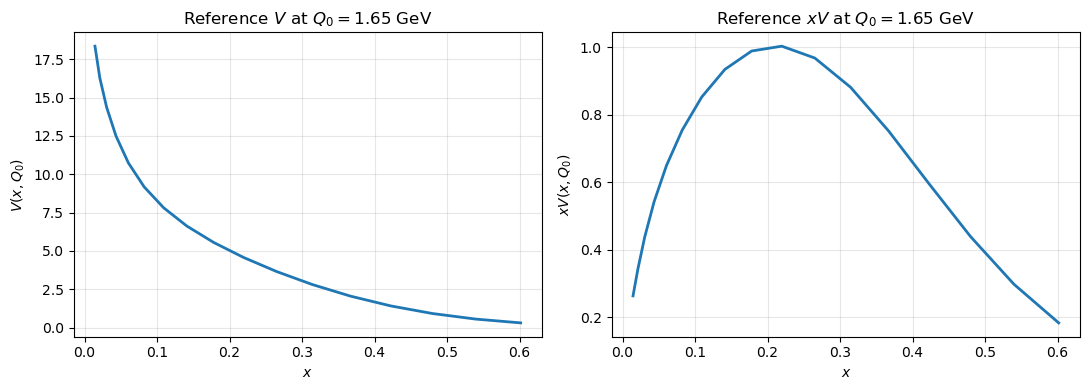

c=0 reference chi2/N = 724.204/67 = 10.809
Generating-mean chi2/N = 56.197/67 = 0.839


In [64]:
pdfset = str(archive["pdfset"])
pdf_member = int(archive["pdf_member"])
pdf = lhapdf.mkPDF(pdfset, pdf_member)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, v_reference, lw=2)
axes[0].set(xlabel="$x$", ylabel="$V(x,Q_0)$", title=fr"Reference $V$ at $Q_0={Q0:g}$ GeV")
axes[1].plot(grid, xv_reference, lw=2)
axes[1].set(xlabel="$x$", ylabel="$xV(x,Q_0)$", title=fr"Reference $xV$ at $Q_0={Q0:g}$ GeV")
for ax in axes:
    #ax.set_xscale("log")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sigma_factor = cho_factor(Sigma)
chi2_reference = (D - prediction_reference) @ cho_solve(sigma_factor, D - prediction_reference)
chi2_generation = (D - mu_pseudo) @ cho_solve(sigma_factor, D - mu_pseudo)
print(f"c=0 reference chi2/N = {chi2_reference:.3f}/{len(D)} = {chi2_reference/len(D):.3f}")
if data_mode == "pseudo":
    print(f"Generating-mean chi2/N = {chi2_generation:.3f}/{len(D)} = {chi2_generation/len(D):.3f}")

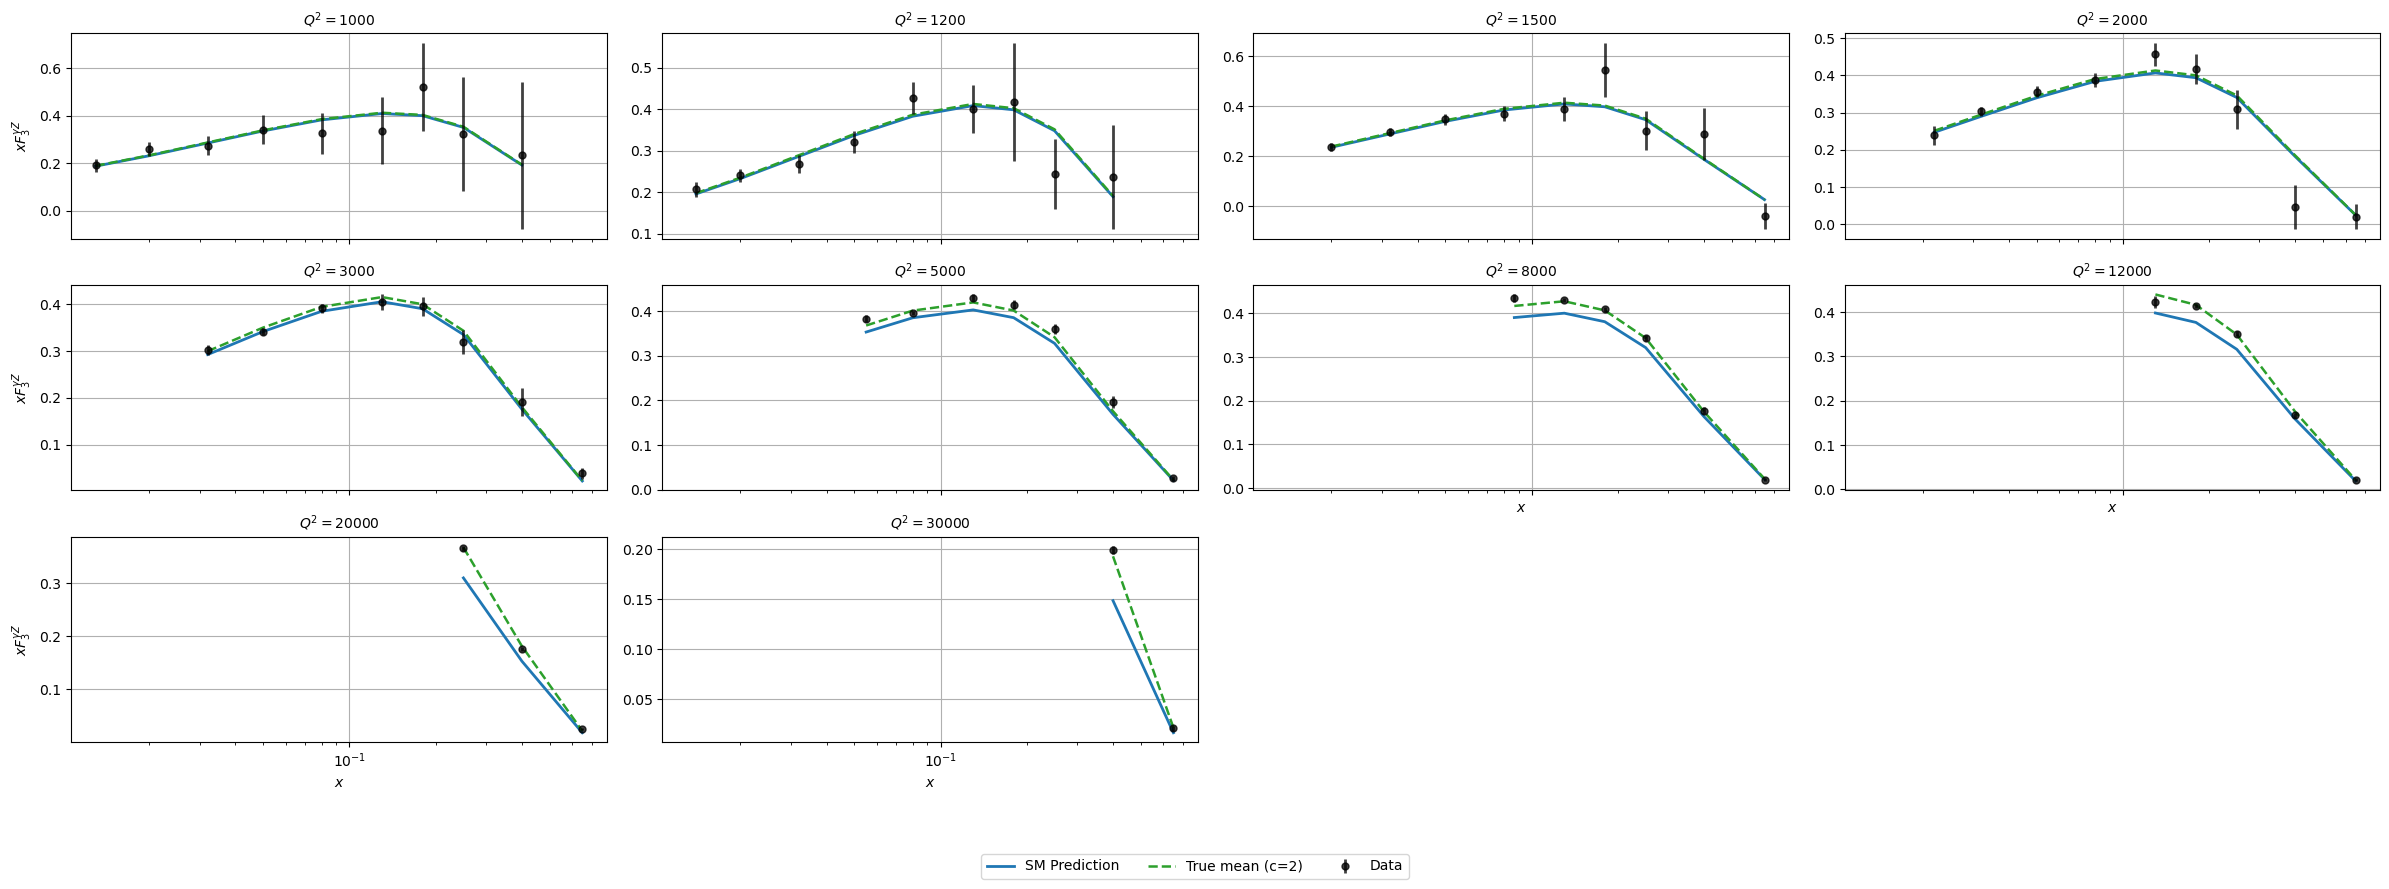

In [65]:
one_sigma_alpha = 2.0 * (1.0 - norm.cdf(1.0))

fig = plot_by_Q2(
    {"SM Prediction": prediction_reference, f"True mean (c={c_true:g})": mu_pseudo, "Data": D},
    xQ2=xQ2, ncols=4, x_log_scale=True, alpha=one_sigma_alpha,
    y_label_first_column_only=True, legend_mode="figure",
    series_styles={
        "SM Prediction": dict(color="C0", linewidth=2),
        f"True mean (c={c_true:g})": dict(color="C2", linewidth=1.8, linestyle="--"),
        "Data": dict(kind="scatter", cov=Sigma, color="black", s=25, alpha=0.75),
    },
    y_label=r"$xF_3^{\gamma Z}$",
)

---
## 4. B-spline representation of $xV$

The primary parametrization is

$$xV(x)=\sum_{k=1}^M\beta_k B_k(x), \qquad A_{ik}=\sum_j W_{ij}B_k(x_j).$$

The full proton valence sum rule is

$$\int_0^1 V(x)\,dx=\int_0^1\frac{xV(x)}{x}\,dx=3.$$

When the fit is restricted to the measured $x$ range, the NNPDF integral in the fixed low- and high-$x$ regions is subtracted from 3. The spline is constrained only to the remaining fitted-range valence number. Set `enforce_sum_rule=False` to remove the constraint. With `match_fixed_tails=True`, the fitted spline is also constrained to equal the fixed reference PDF at both boundaries of the fitted range.

In [66]:
degree = 3
M = 8
parametrize = "xV"  # alternatively: "V"
enforce_sum_rule = True
nonnegative_pdf = True
match_fixed_tails = True  # enforce C0 continuity when fitting a restricted x range

x_min, x_max = float(grid.min()), float(grid.max())
sum_rule_total = 3.0
if restrict_to_data_x_range:
    # Integrate in log(x): V(x) dx = xV(x) dlog(x). This is much more
    # stable than dividing by x and integrating directly near x=0.
    def xv_reference_lhapdf(log_x):
        z = np.exp(log_x)
        return sum(
            pdf.xfxQ(pid, z, Q0) - pdf.xfxQ(-pid, z, Q0)
            for pid in (1, 2, 3, 4)
        )

    fixed_sum_low = quad(
        xv_reference_lhapdf, np.log(float(pdf.xMin)), np.log(x_min), limit=300
    )[0]
    fixed_sum_high = quad(
        xv_reference_lhapdf, np.log(x_max), 0.0, limit=300
    )[0]
else:
    fixed_sum_low = fixed_sum_high = 0.0
sum_rule_value = sum_rule_total - fixed_sum_low - fixed_sum_high

B = bspline_basis(degree, M, x_min, x_max)
B_grid = np.vstack([Bk(grid) for Bk in B])

if parametrize == "xV":
    # W multiplies xV directly.
    A_full = W @ B_grid.T
    integral_weights_full = np.array([
        quad(lambda z, Bk=Bk: Bk(z) / z, x_min, x_max)[0]
        for Bk in B
    ])
    boundary_values = np.array([xv_reference[0], xv_reference[-1]])
elif parametrize == "V":
    # xV = x * V.
    A_full = W @ (grid[:, None] * B_grid.T)
    integral_weights_full = np.array([Bk.integrate(x_min, x_max) for Bk in B])
    boundary_values = np.array([v_reference[0], v_reference[-1]])
else:
    raise ValueError("parametrize must be 'xV' or 'V'")

# A clamped B-spline satisfies f(x_min)=beta[0] and
# f(x_max)=beta[-1]. For boundary continuity, fix those coefficients to the
# reference values and fit only the interior coefficients. Their known
# data-level contribution is part of the fixed term inside the EFT factor.
continuity_constraint = bool(match_fixed_tails and restrict_to_data_x_range)
beta_fixed = np.zeros(M)
if continuity_constraint:
    beta_fixed[[0, -1]] = boundary_values
    free_basis_indices = np.arange(1, M - 1)
else:
    free_basis_indices = np.arange(M)

A = A_full[:, free_basis_indices]
integral_weights = integral_weights_full[free_basis_indices]
fixed_boundary_prediction = A_full @ beta_fixed
eft_fixed_offset = target_offset + eft_background + fixed_boundary_prediction

fixed_boundary_integral = float(integral_weights_full @ beta_fixed)
free_sum_rule_value = sum_rule_value - fixed_boundary_integral
if enforce_sum_rule and free_sum_rule_value <= 0:
    raise ValueError("Fixed boundary contribution exhausts the fitted-range sum rule")
# utils enforces w_norm @ beta_free = 1.
w_norm = integral_weights / free_sum_rule_value if enforce_sum_rule else None

# The continuity endpoints have already been removed from the fitted
# parameter vector. Retain the old zero-endpoint behavior only when the
# full x range is fitted without the continuity construction.
pin_endpoints = bool(not continuity_constraint and not restrict_to_data_x_range)

def reconstruct_full_beta(beta_free):
    beta_free = np.asarray(beta_free, dtype=float)
    if not continuity_constraint:
        return beta_free.copy()
    beta_full = beta_fixed.copy()
    beta_full[free_basis_indices] = beta_free
    return beta_full

def fitted_range_valence(beta_free):
    return float(integral_weights_full @ reconstruct_full_beta(beta_free))

print(f"Parametrization: {parametrize}; fitted A shape: {A.shape}; full basis: {M}")
print(f"Enforce V sum rule (integral = {sum_rule_value:g}):", enforce_sum_rule)
print(f"Fixed outside-range valence integral = {fixed_sum_low + fixed_sum_high:.8f}")
print("Match fitted PDF to fixed tails:", continuity_constraint)
if continuity_constraint:
    print(f"Boundary values ({parametrize}) = {boundary_values}")
    print(f"Fixed boundary-basis integral = {fixed_boundary_integral:.8f}")
print("Pin remaining spline endpoints to zero:", pin_endpoints)
print("Condition number of A:", np.linalg.cond(A))

Parametrization: xV; fitted A shape: (67, 6); full basis: 8
Enforce V sum rule (integral = 2.43842): True
Fixed outside-range valence integral = 0.56158065
Match fitted PDF to fixed tails: True
Boundary values (xV) = [0.26383409 0.18384668]
Fixed boundary-basis integral = 0.26760118
Pin remaining spline endpoints to zero: False
Condition number of A: 86.30383182239517


---
## 5. Fits to the pseudo-data

### 5a. Separate fit

First fit the spline coefficients at $c=0$, then fit $c$ with the PDF fixed. The likelihood uses `D_fit`, from which only `additive_background` has been removed. Any background selected to be inside the EFT factor is retained in `eft_fixed_offset`.

In [67]:
c0 = 0.0
loss_scale = 1e2  # improves optimizer scaling

beta_hat_sep, beta_history = mle_beta(
    D=D_fit, A=A, c=c0, v=_v_c, xQ2=xQ2, Sigma=Sigma,
    w_norm=w_norm, nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
    beta_opt="SLSQP", return_history=True, loss_scale=loss_scale,
    eft_offset=eft_fixed_offset,
)

c_hat_sep = mle_c(
    D=D_fit, A=A, v=_v_c, beta=beta_hat_sep, xQ2=xQ2, Sigma=Sigma,
    c_opt="Nelder-Mead", c_range=(-20, 20), eft_offset=eft_fixed_offset,
)

print(f"True c = {c_true:.6g}")
print(f"Separate-fit c = {c_hat_sep:.6g} (error {c_hat_sep - c_true:+.6g})")
if w_norm is not None:
    print(f"V sum rule = {fitted_range_valence(beta_hat_sep):.8f}")

True c = 2
Separate-fit c = 0.596688 (error -1.40331)
V sum rule = 2.43841935


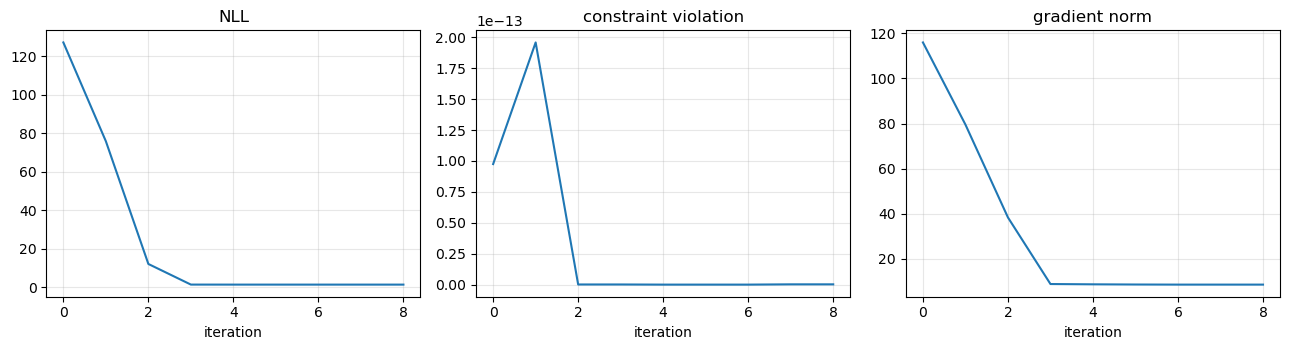

In [68]:
history_sep = pd.DataFrame(beta_history)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column, title in zip(axes, ["loss", "constr_viol", "grad_norm"], ["NLL", "constraint violation", "gradient norm"]):
    ax.plot(history_sep[column])
    ax.set(title=title, xlabel="iteration")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5b. Joint fit

Fit the spline coefficients and $c$ simultaneously.

In [69]:
joint_result, joint_history = fit_beta_c(
    D=D_fit, A=A, v=_v_c, v_prime=_v_prime_c, c0=c0,
    w_norm=w_norm, xQ2=xQ2, Sigma=Sigma,
    nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
    return_history=True, opt_method="SLSQP", loss_scale=loss_scale,
    eft_offset=eft_fixed_offset,
)

beta_hat_joint = joint_result.beta_hat
c_hat_joint = joint_result.c_hat
print("Optimizer success:", joint_result.success, "-", joint_result.message)
print(f"True c = {c_true:.6g}")
print(f"Joint-fit c = {c_hat_joint:.6g} (error {c_hat_joint - c_true:+.6g})")
if w_norm is not None:
    print(f"V sum rule = {fitted_range_valence(beta_hat_joint):.8f}")

Optimizer success: True - Optimization terminated successfully
True c = 2
Joint-fit c = 1.99279 (error -0.00720606)
V sum rule = 2.43841935


Choose the default MLE used by the fitted-model curve and the backward-compatible scalar result aliases. One-step estimates are computed for both fit methods so the Results plot can select either one.

In [70]:
fit_method = "separate"  # "separate" or "joint"

if fit_method == "separate":
    beta_hat, c_hat = beta_hat_sep, c_hat_sep
elif fit_method == "joint":
    beta_hat, c_hat = beta_hat_joint, c_hat_joint
else:
    raise ValueError("fit_method must be 'separate' or 'joint'")

### 5c. One-step estimator

In [71]:
# Compute the one-step estimate from both MLE starting points so that the
# Results plot can select separate and joint entries independently.
one_realization_results = {}
for method, beta_mle, c_mle in [
    ("separate", beta_hat_sep, c_hat_sep),
    ("joint", beta_hat_joint, c_hat_joint),
]:
    K_method = build_K_matrix(c_mle, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
    K_prime_method = build_K_prime_matrix(
        c_mle, A, xQ2=xQ2, klin=_klin, kquad=_kquad
    )
    fixed_mean_method = _v_c(c_mle, xQ2) * eft_fixed_offset
    fixed_mean_prime_method = _v_prime_c(c_mle, xQ2) * eft_fixed_offset
    c_os_method, info_method = one_step_c(
        D_fit, K_method, K_prime_method, beta_mle, c_mle, w_norm=w_norm,
        s2_diag=np.diag(Sigma), pin_endpoints=pin_endpoints,
        fixed_mean=fixed_mean_method,
        fixed_mean_prime=fixed_mean_prime_method,
    )
    ci_os_method = one_step_confidence_interval(info_method)
    one_realization_results[method] = {
        "beta": beta_mle, "plug_in": c_mle,
        "one_step": c_os_method, "one_step_info": info_method,
        "ci_one_step": ci_os_method[:2], "one_step_se": ci_os_method[2],
        "ci_mle": None, "ci_mle_method": None, "mle_se": None,
        "ci_mle_asymptotic": None, "mle_se_asymptotic": None,
        "ci_mle_bootstrap": None, "mle_se_bootstrap": None,
        "mle_ci_info": None, "boot_samples": None,
    }

# Preserve the original aliases for the fit selected above.
selected_result = one_realization_results[fit_method]
c_one_step = selected_result["one_step"]
one_step_info = selected_result["one_step_info"]
ci_os_lower, ci_os_upper = selected_result["ci_one_step"]
se_os = selected_result["one_step_se"]

print(f"True c                    = {c_true:.6g}")
print(f"MLE c ({fit_method}) = {c_hat:.6g} (error {c_hat - c_true:+.6g})")
print(f"One-step c                 = {c_one_step:.6g} (error {c_one_step - c_true:+.6g})")
print(f"EIF correction         = {one_step_info['eif']:.6g}")
print(f"95% CI      = [{ci_os_lower:.6g}, {ci_os_upper:.6g}]")

True c                    = 2
MLE c (separate) = 0.596688 (error -1.40331)
One-step c                 = 2.00151 (error +0.00151096)
EIF correction         = 1.40482
95% CI      = [1.66298, 2.34004]


### Optional parametric-bootstrap interval

Use `one_realization_ci_plot` to select separate/joint MLE or one-step entries. The separate MLE uses a parametric bootstrap. Set `joint_mle_ci_method` to `"bootstrap"`, `"asymptotic"`, or `"both"` for the joint MLE; one-step intervals are analytical.

In [79]:
# Select the entries to show in the one-realization Results plot.
# This uses the same (method, estimator) convention as the simulation plot.
one_realization_ci_plot = [
    ("separate", "plug_in"),
    ("separate", "one_step"),
    ("joint", "plug_in"),
]

# The separate MLE currently uses bootstrap inference. For the joint MLE,
# choose "bootstrap", "asymptotic", or "both".
run_bootstrap = True
joint_mle_ci_method = "both"  # "bootstrap", "asymptotic", or "both"
joint_mle_hessian_method = "numerical"  # "analytical" or "numerical"
one_realization_joint_mle_ci_plot_methods = ("asymptotic",)
one_realization_n_boot = 500
if joint_mle_ci_method not in {"bootstrap", "asymptotic", "both"}:
    raise ValueError(
        "joint_mle_ci_method must be 'bootstrap', 'asymptotic', or 'both'."
    )
if joint_mle_hessian_method not in {"analytical", "numerical"}:
    raise ValueError(
        "joint_mle_hessian_method must be 'analytical' or 'numerical'."
    )
available_joint_ci_methods = (
    {"bootstrap", "asymptotic"}
    if joint_mle_ci_method == "both" else {joint_mle_ci_method}
)
if (not one_realization_joint_mle_ci_plot_methods or
        not set(one_realization_joint_mle_ci_plot_methods) <= available_joint_ci_methods):
    raise ValueError(
        "one_realization_joint_mle_ci_plot_methods must be a nonempty subset "
        "of the joint-MLE CI methods being computed."
    )

valid_estimators = {"plug_in", "one_step"}
for method, estimator in one_realization_ci_plot:
    if method not in one_realization_results:
        raise ValueError(f"Unknown fit method {method!r}; use 'separate' or 'joint'.")
    if estimator not in valid_estimators:
        raise ValueError(
            f"Unknown estimator {estimator!r}; use 'plug_in' or 'one_step'."
        )

# Compute an interval only for MLE methods requested in the Results plot.
mle_methods_for_ci = list(dict.fromkeys(
    method for method, estimator in one_realization_ci_plot
    if estimator == "plug_in"
))
for method in mle_methods_for_ci:
    result = one_realization_results[method]
    if method == "joint" and joint_mle_ci_method in {"asymptotic", "both"}:
        lo, hi, se, ci_info = joint_mle_asymptotic_confidence_interval(
            A=A, xQ2=xQ2, Sigma=Sigma, c_hat=result["plug_in"],
            beta_hat=result["beta"], v=_v_c, v_prime=_v_prime_c,
            D=D_fit, v_second=_v_second_c,
            w_norm=w_norm, eft_offset=eft_fixed_offset,
            pin_endpoints=pin_endpoints, alpha=0.05,
            hessian_method=joint_mle_hessian_method,
        )
        result["ci_mle_asymptotic"] = (lo, hi)
        result["mle_se_asymptotic"] = se
        result["mle_ci_info"] = ci_info
        print(
            f"[joint] MLE asymptotic ({joint_mle_hessian_method} Hessian) "
            f"95% CI = [{lo:.6g}, {hi:.6g}]"
        )
    if run_bootstrap and (
        method == "separate"
        or joint_mle_ci_method in {"bootstrap", "both"}
    ):
        lo, hi, samples = bootstrap_confidence_interval(
            A=A, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, c0=c0,
            c_hat=result["plug_in"], beta_hat=result["beta"],
            n_boot=one_realization_n_boot, alpha=0.05, estimator="mle",
            klin=_klin, kquad=_kquad, nonneg_beta=nonnegative_pdf,
            pin_endpoints=pin_endpoints, opt=method, c_opt="L-BFGS-B",
            c_range=(-20, 20), beta_opt="SLSQP", loss_scale=loss_scale,
            verbose=True, eft_offset=eft_fixed_offset,
        )
        result["ci_mle_bootstrap"] = (lo, hi)
        result["mle_se_bootstrap"] = np.nanstd(samples, ddof=1)
        result["boot_samples"] = samples
        print(f"[{method}] MLE bootstrap 95% CI = [{lo:.6g}, {hi:.6g}]")
    elif method == "separate":
        print(f"Skipping {method} MLE CI because run_bootstrap=False.")

    # Backward-compatible alias: prefer asymptotic when both were requested.
    if result["ci_mle_asymptotic"] is not None:
        result["ci_mle"] = result["ci_mle_asymptotic"]
        result["mle_se"] = result["mle_se_asymptotic"]
        result["ci_mle_method"] = "Asymptotic"
    elif result["ci_mle_bootstrap"] is not None:
        result["ci_mle"] = result["ci_mle_bootstrap"]
        result["mle_se"] = result["mle_se_bootstrap"]
        result["ci_mle_method"] = "Parametric bootstrap"

# Preserve scalar aliases for the selected fit method.
if one_realization_results[fit_method]["ci_mle"] is not None:
    ci_mle_lower, ci_mle_upper = one_realization_results[fit_method]["ci_mle"]
    bootstrap_samples = one_realization_results[fit_method]["boot_samples"]

  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
[separate] MLE bootstrap 95% CI = [0.514666, 0.678709]
[joint] MLE asymptotic (numerical Hessian) 95% CI = [1.67052, 2.31507]
  Bootstrap replicate 50/500
  Bootstrap replicate 100/500
  Bootstrap replicate 150/500
  Bootstrap replicate 200/500
  Bootstrap replicate 250/500
  Bootstrap replicate 300/500
  Bootstrap replicate 350/500
  Bootstrap replicate 400/500
  Bootstrap replicate 450/500
  Bootstrap replicate 500/500
[joint] MLE bootstrap 95% CI = [1.6946, 2.29099]


---
## 6. Results

saved figure at: ../results/HERA/V_fit_c=2_Lambda=500.pdf


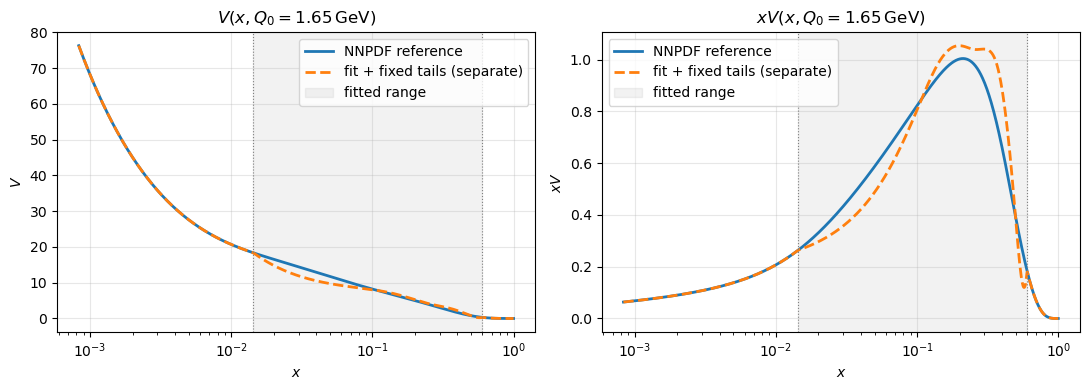

Fitted boundary values (xV): [0.26383409 0.18384668]
Fixed-tail boundary values (xV): [0.26383409 0.18384668]


In [75]:
# Show the complete FK-grid range. Within [x_min, x_max] use the fitted
# spline; outside it use the same fixed NNPDF PID-200 PDF that enters
# target_offset.
plot_x = np.geomspace(float(grid_full.min()), float(grid_full.max()), 1000)
fit_plot_mask = (plot_x >= x_min) & (plot_x <= x_max)

xv_reference_plot = np.array([
    sum(
        pdf.xfxQ(pid, z, Q0) - pdf.xfxQ(-pid, z, Q0)
        for pid in (1, 2, 3, 4)
    )
    for z in plot_x
])
v_reference_plot = xv_reference_plot / plot_x

basis_fit_plot = np.vstack([Bk(plot_x[fit_plot_mask]) for Bk in B])
beta_hat_full = reconstruct_full_beta(beta_hat)
fit_basis = beta_hat_full @ basis_fit_plot

xv_hat_plot = xv_reference_plot.copy()
v_hat_plot = v_reference_plot.copy()
if parametrize == "xV":
    xv_hat_plot[fit_plot_mask] = fit_basis
    v_hat_plot[fit_plot_mask] = fit_basis / plot_x[fit_plot_mask]
else:
    v_hat_plot[fit_plot_mask] = fit_basis
    xv_hat_plot[fit_plot_mask] = plot_x[fit_plot_mask] * fit_basis

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(plot_x, v_reference_plot, lw=2, label="NNPDF reference")
axes[0].plot(plot_x, v_hat_plot, lw=2, ls="--", label=fr"fit + fixed tails ({fit_method})")
axes[0].set(xlabel="$x$", ylabel="$V$", title=fr"$V(x,Q_0={Q0:g}\,\mathrm{{GeV}})$")
axes[1].plot(plot_x, xv_reference_plot, lw=2, label="NNPDF reference")
axes[1].plot(plot_x, xv_hat_plot, lw=2, ls="--", label=fr"fit + fixed tails ({fit_method})")
axes[1].set(xlabel="$x$", ylabel="$xV$", title=fr"$xV(x,Q_0={Q0:g}\,\mathrm{{GeV}})$")
for ax in axes:
    ax.axvspan(x_min, x_max, color="gray", alpha=0.10, label="fitted range")
    ax.axvline(x_min, color="gray", lw=0.8, ls=":")
    ax.axvline(x_max, color="gray", lw=0.8, ls=":")
    ax.set_xscale("log")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
if save_fig:
    output = f"../results/HERA/V_fit_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(output, 
            format="pdf", bbox_inches="tight")
    print("saved figure at:", output)
plt.show()

# Verify the continuity at the exact fitted-range boundaries.
fitted_boundary_values = np.array([
    beta_hat_full @ np.array([Bk(x_min) for Bk in B]),
    beta_hat_full @ np.array([Bk(x_max) for Bk in B]),
])
print(f"Fitted boundary values ({parametrize}):", fitted_boundary_values)
print(f"Fixed-tail boundary values ({parametrize}):", boundary_values)
if continuity_constraint:
    assert np.allclose(fitted_boundary_values, boundary_values, rtol=1e-10, atol=1e-12)

Separate MLE chi2/N = 193.002/67 = 2.881
Joint MLE chi2/N = 56.976/67 = 0.850
True mean chi2/N = 56.197/67 = 0.839
Figure saved at: ../results/HERA/data_fit_c=2_Lambda=500.pdf


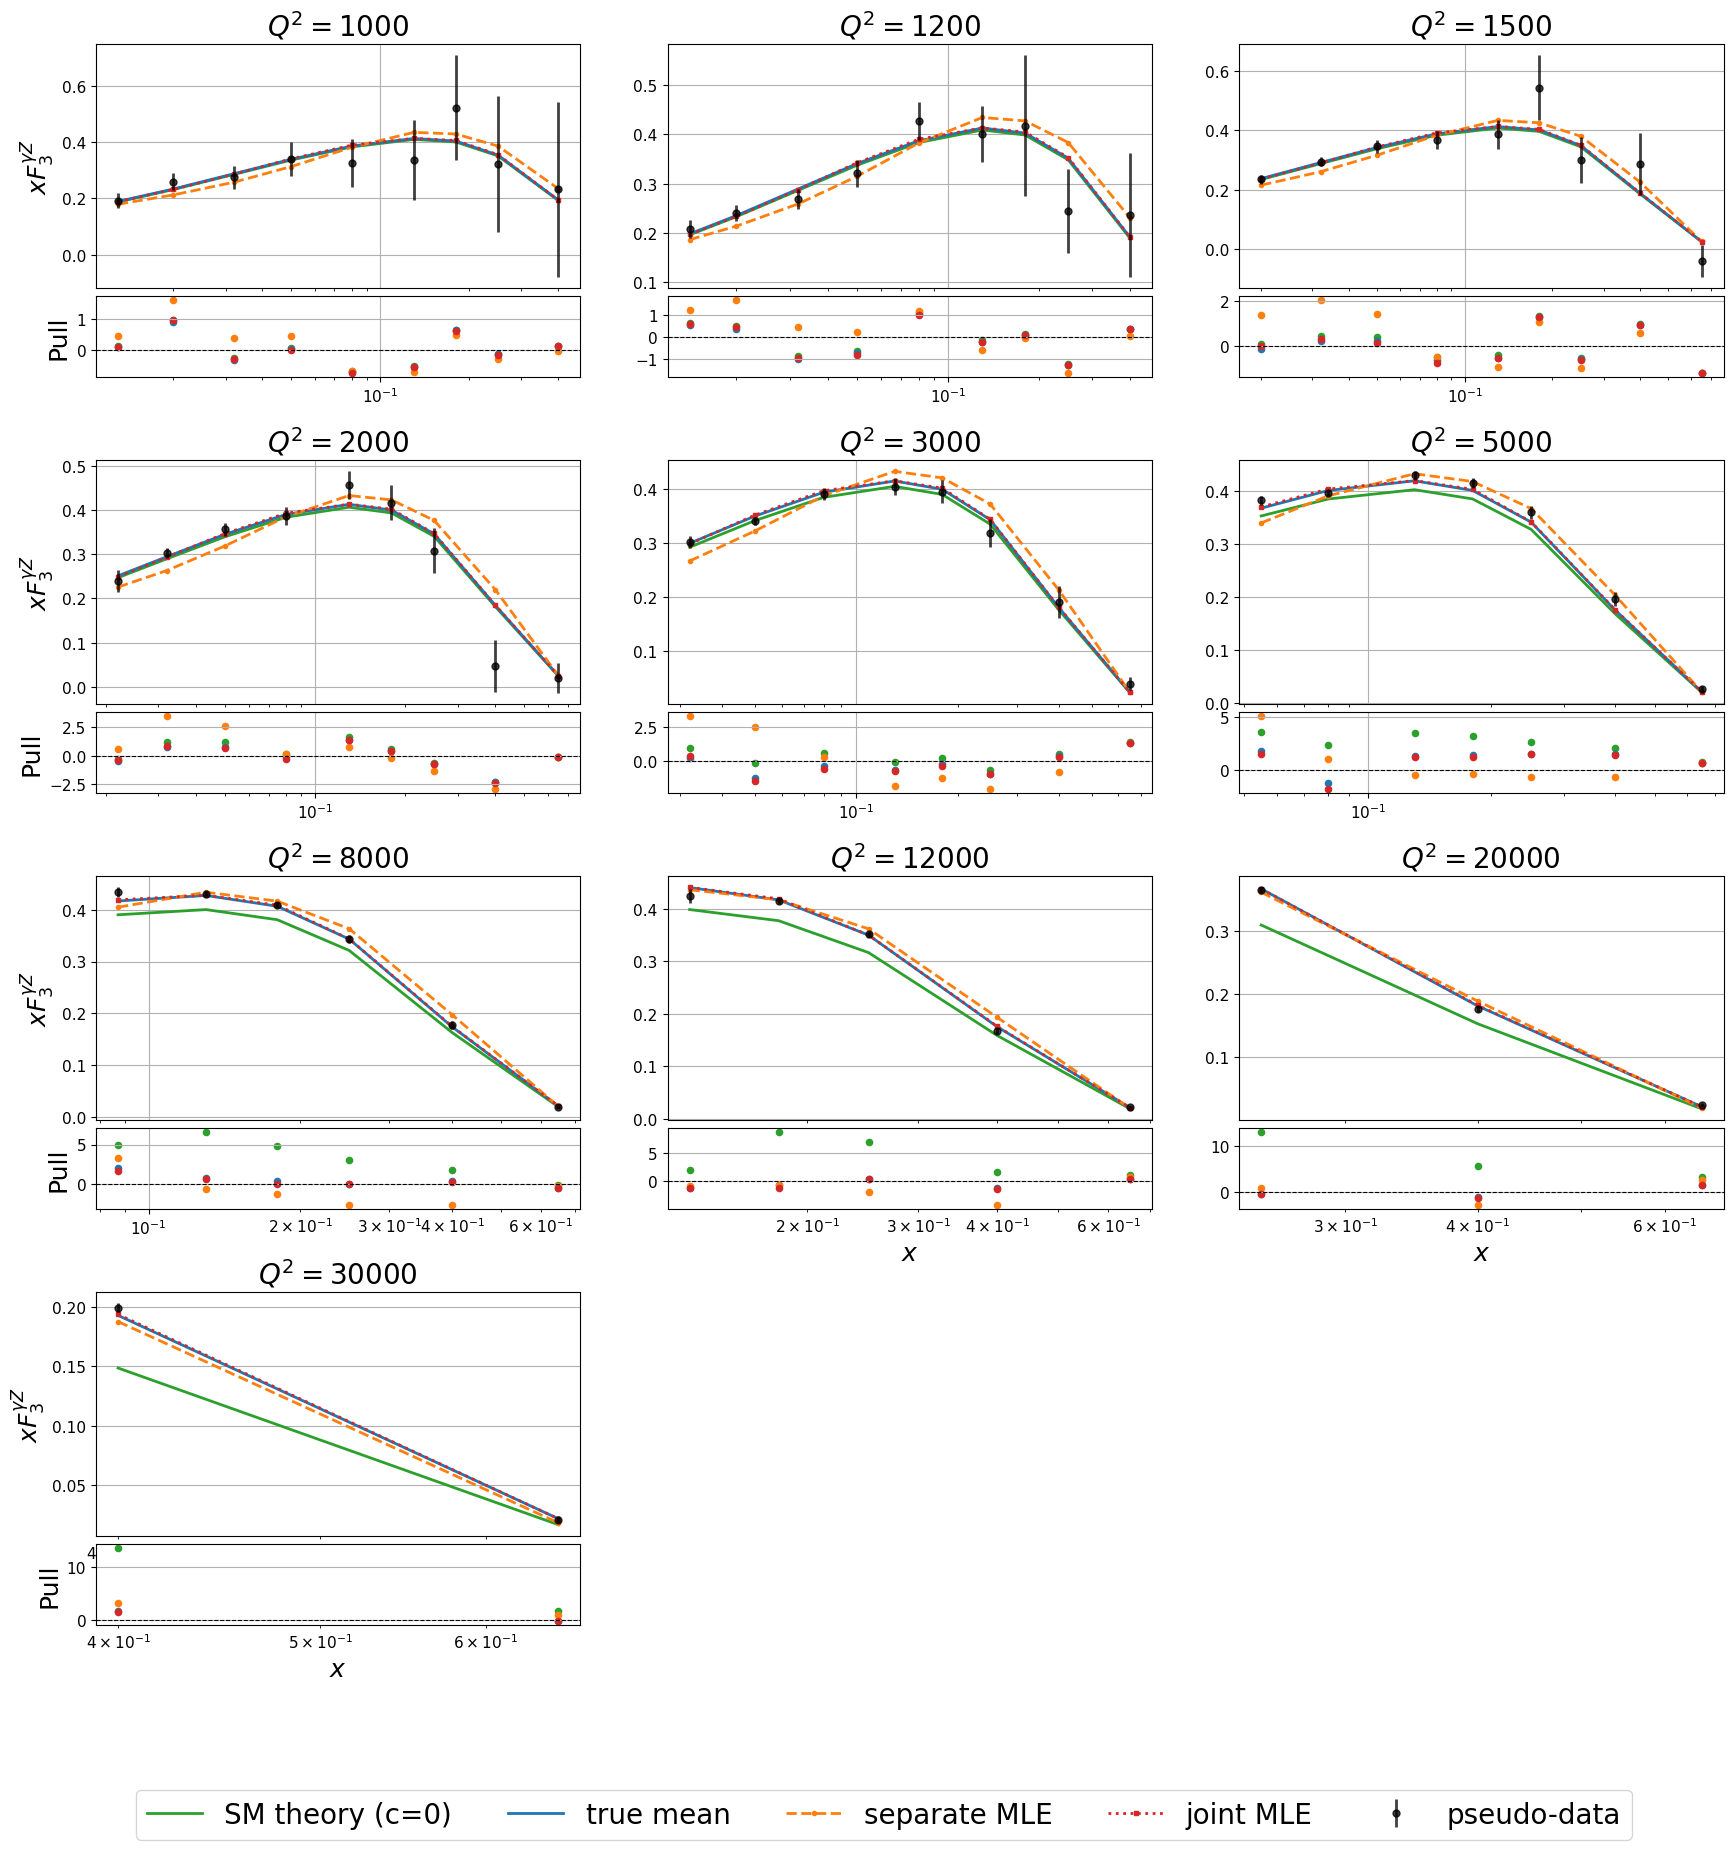

In [80]:
# Construct the data-level prediction for each MLE fitting strategy.
fit_predictions = {}
for method, c_mle, beta_mle in [
    ("Separate MLE", c_hat_sep, beta_hat_sep),
    ("Joint MLE", c_hat_joint, beta_hat_joint),
]:
    eft_prediction = _v_c(c_mle, xQ2) * (
        A @ beta_mle + eft_fixed_offset
    )
    fit_predictions[method] = additive_background + eft_prediction

# Preserve the selected-fit alias used elsewhere in the notebook.
full_fit_prediction = fit_predictions[
    "Separate MLE" if fit_method == "separate" else "Joint MLE"
]

# Report the data-level chi-square for both fits.
for method, prediction in fit_predictions.items():
    residual = D - prediction
    chi2 = residual @ cho_solve(cho_factor(Sigma), residual)
    print(
        f"{method} chi2/N = {chi2:.3f}/{len(D)} = "
        f"{chi2 / len(D):.3f}"
    )
print(
    f"True mean chi2/N = {chi2_generation:.3f}/{len(D)} = "
    f"{chi2_generation / len(D):.3f}"
)

one_sigma_alpha = 2.0 * (1.0 - norm.cdf(1.0))
fig = plot_by_Q2(
    {
        "SM theory (c=0)": prediction_reference,
        "true mean": mu_pseudo,
        "separate MLE": fit_predictions["Separate MLE"],
        "joint MLE": fit_predictions["Joint MLE"],
        "pseudo-data": D,
    },
    xQ2=xQ2, ncols=3, x_log_scale=True, alpha=one_sigma_alpha,
    y_label_first_column_only=True, legend_mode="figure", legend_fontsize=20,
    title_fontsize=20, label_fontsize=18,
    series_styles={
        "SM theory (c=0)": dict(linestyle="-", linewidth=2, color="C2"),
        "true mean": dict(color="C0", linewidth=2),
        "separate MLE": dict(
            color="C1", linestyle="--", linewidth=2,
            marker="o", markersize=3,
        ),
        "joint MLE": dict(
            color="C3", linestyle=":", linewidth=2,
            marker="s", markersize=3,
        ),
        "pseudo-data": dict(
            kind="scatter", cov=Sigma, color="black", s=25, alpha=0.75,
        ),
    },
    pull=[
        {"data": "pseudo-data", "ref": "SM theory (c=0)", "color": "C2"},
        {"data": "pseudo-data", "ref": "true mean", "color": "C0"},
        {"data": "pseudo-data", "ref": "separate MLE", "color": "C1"},
        {"data": "pseudo-data", "ref": "joint MLE", "color": "C3"},
    ],
    y_label=r"$xF_3^{\gamma Z}$",
)
outer_grid = fig.axes[0].get_subplotspec().get_topmost_subplotspec().get_gridspec()
fig.set_size_inches(7 * outer_grid.ncols, 5.2 * outer_grid.nrows)
outer_grid.update(wspace=0.18, hspace=0.25)
# Enlarge tick labels on both the main and pull axes.
for ax in fig.axes:
    ax.tick_params(axis="both", which="both", labelsize=11)
    ax.xaxis.get_offset_text().set_fontsize(24)
    ax.yaxis.get_offset_text().set_fontsize(24)

if save_fig:
    output = f"../results/HERA/data_fit_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(
        output,
        format="pdf", bbox_inches="tight",
    )
    print("Figure saved at:", output)

,estimate,error,CI lower,CI upper,CI method
result,,,,,
Truth,2.000000,0.000000,NaN,NaN,None
Separate fit (bootstrap),0.596688,-1.403312,0.514666,0.678709,Parametric bootstrap
Joint fit (asymptotic),1.992794,-0.007206,1.670520,2.315068,Asymptotic (observed Hessian)
Joint fit (bootstrap),1.992794,-0.007206,1.694596,2.290991,Parametric bootstrap
One-step (separate),2.001511,0.001511,1.662982,2.340039,Analytical one-step


Figured saved at: ../results/HERA/CI95_c=2_Lambda=500.pdf


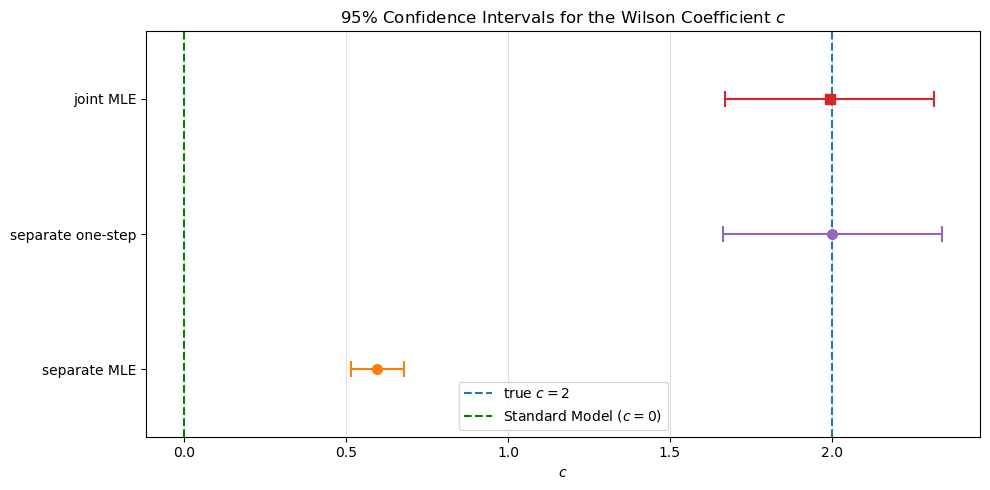

In [91]:
summary_rows = [{
    "result": "Truth", "estimate": c_true,
    "CI lower": np.nan, "CI upper": np.nan, "CI method": None,
}]
for method, row_label in [("separate", "Separate fit"), ("joint", "Joint fit")]:
    result = one_realization_results[method]
    for ci_method, ci, method_label in [
        ("asymptotic", result.get("ci_mle_asymptotic"),
         "Asymptotic (observed Hessian)"),
        ("bootstrap", result.get("ci_mle_bootstrap"),
         "Parametric bootstrap"),
    ]:
        if ci is None:
            continue
        summary_rows.append({
            "result": f"{row_label} ({ci_method})",
            "estimate": result["plug_in"],
            "CI lower": ci[0], "CI upper": ci[1],
            "CI method": method_label,
        })
summary_rows.append({
    "result": f"One-step ({fit_method})", "estimate": c_one_step,
    "CI lower": ci_os_lower, "CI upper": ci_os_upper,
    "CI method": "Analytical one-step",
})
summary = pd.DataFrame(summary_rows).set_index("result")
summary.insert(1, "error", summary["estimate"] - c_true)
display(summary)

# Plot the selected one-realization confidence intervals.
estimator_colors = {"plug_in": "C1", "one_step": "C4"}
method_markers = {"separate": "o", "joint": "s"}
estimator_labels = {"plug_in": "MLE", "one_step": "one-step"}
ci_comparison = []
for method, estimator in one_realization_ci_plot:
    result = one_realization_results[method]
    if estimator == "plug_in":
        ci_entries = [
            ("asymptotic", result.get("ci_mle_asymptotic")),
            ("bootstrap", result.get("ci_mle_bootstrap")),
        ]
        ci_entries = [(name, ci) for name, ci in ci_entries if ci is not None]
        if method == "joint":
            ci_entries = [
                (name, ci) for name, ci in ci_entries
                if name in one_realization_joint_mle_ci_plot_methods
            ]
    else:
        ci_entries = [(None, result["ci_one_step"])]
    if not ci_entries:
        print(
            f"Skipping {method} {estimator_labels[estimator]}: "
            "no MLE CI is available."
        )
        continue
    for ci_method, ci in ci_entries:
        suffix = f" ({ci_method})" if ci_method is not None else ""
        ci_comparison.append({
            "label": f"{method} {estimator_labels[estimator]}",#{suffix}",
            "estimate": result[estimator], "lower": ci[0], "upper": ci[1],
            "color": (
                "C3" if method == "joint" and estimator == "plug_in"
                else estimator_colors[estimator]
            ),
            "marker": method_markers[method],
        })

if not ci_comparison:
    raise ValueError("None of the selected entries has a confidence interval to plot.")

labels = [item["label"] for item in ci_comparison]
y = np.arange(len(ci_comparison))
fig, ax = plt.subplots(figsize=(10, 5))
for i, item in enumerate(ci_comparison):
    estimate = item["estimate"]
    ax.errorbar(
        estimate, y[i],
        xerr=[[estimate - item["lower"]], [item["upper"] - estimate]],
        fmt=item["marker"], capsize=6, capthick=1.5, linewidth=1.5,
        color=item["color"], markersize=7,
    )
ax.axvline(c_true, color="C0", linestyle="--", linewidth=1.5,
           label=fr"true $c = {c_true}$")
ax.axvline(0, color="green", linestyle="--", linewidth=1.5,
           label=r"Standard Model ($c = 0$)")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_ylim(-0.5, len(labels) - 0.5)
ax.set_xlabel(r"$c$")
ax.set_title(r"95% Confidence Intervals for the Wilson Coefficient $c$")
ax.legend()
ax.grid(True, axis="x", alpha=0.4)
plt.tight_layout()
if save_fig:
    ci_plot_output = f"../results/HERA/CI95_c={c_true}_Lambda={int(Lambda)}.pdf"
    fig.savefig(ci_plot_output, format="pdf", bbox_inches="tight")
    print(f"Figured saved at: {ci_plot_output}")
plt.show()

---
## 7. Simulation study

Repeat the closure test with independent draws from the same generating model. Each replicate is generated for the background placement selected above as

$$D_{\mathrm{fit}}^{(s)}\sim\mathcal N\!\left(v(c_{\rm true};Q^2)\left(W_{\rm sub}[xV^{\rm ref}]+t^{\rm fixed}+b_{\rm EFT}\right),\Sigma\right).$$

`setup_experiment` stores the V basis, restricted design matrix, fixed-tail contribution, and generating mean once. `run_single_experiment` then draws new data and reruns only the fit and one-step update.

Set `simulation_fit_method` to `"joint"`, `"separate"`, or `"both"`. In `"both"` mode, the two fits use the same pseudo-data draw in every replicate, enabling a paired comparison. Bootstrap intervals are available but disabled by default because they require a nested set of refits.

In [26]:
run_simulation = True
N_sim = 1000
simulation_seed = 1
simulation_fit_method = "both"  # "separate", "joint", or "both"
# Separate-MLE intervals remain bootstrap-based. The joint-MLE interval
# can use the nested bootstrap, the asymptotic interval, or both.
compute_bootstrap_coverage = True
simulation_joint_mle_ci_method = "both"  # "bootstrap", "asymptotic", or "both"
simulation_joint_mle_hessian_method = "numerical"  # "analytical" or "numerical"
n_boot_sim = 500
simulation_progress_every = 20

# Optimizers used by each simulation fitting strategy.
simulation_joint_optimizer = "SLSQP"
simulation_separate_beta_optimizer = "SLSQP"
simulation_separate_c_optimizer = "Nelder-Mead"
simulation_c_range = (-20.0, 40.0)  # used by grid_search
simulation_loss_scale = loss_scale
if simulation_joint_mle_ci_method not in {"bootstrap", "asymptotic", "both"}:
    raise ValueError(
        "simulation_joint_mle_ci_method must be 'bootstrap', 'asymptotic', or 'both'."
    )
if simulation_joint_mle_hessian_method not in {"analytical", "numerical"}:
    raise ValueError(
        "simulation_joint_mle_hessian_method must be 'analytical' or 'numerical'."
    )
if (simulation_joint_mle_ci_method in {"bootstrap", "both"}
        and not compute_bootstrap_coverage):
    raise ValueError(
        "compute_bootstrap_coverage must be True when requesting bootstrap CIs."
    )

if simulation_fit_method == "both":
    simulation_fit_methods = ("separate", "joint")
elif simulation_fit_method in ("separate", "joint"):
    simulation_fit_methods = (simulation_fit_method,)
else:
    raise ValueError("simulation_fit_method must be 'joint', 'separate', or 'both'")

c0 = 0

def validate_v_fit(beta_free):
    # The fixed endpoint coefficients must reproduce the reference tails.
    beta_full = reconstruct_full_beta(beta_free)
    endpoint_basis = np.array([[Bk(x_min), Bk(x_max)] for Bk in B])
    if not np.allclose(beta_full @ endpoint_basis, boundary_values):
        raise ValueError("Fitted V spline does not match the fixed tails")

# V uses a restricted/free basis and known contributions inside the EFT
# factor, so pass those already-computed components to the common setup.
setup_dict = setup_experiment(
    pdf=pdfset, c=c_true, f=lambda z: np.interp(z, grid, xv_reference),
    xQ2=xQ2, grid=grid, W=W, degree=degree, M=8,
    data_Sigma=Sigma, opt=simulation_fit_methods[0],
    c_opt=simulation_separate_c_optimizer, c_range=simulation_c_range,
    beta_opt=simulation_separate_beta_optimizer, c0=c0, Lambda=Lambda,
    x_min=x_min, x_max=x_max, Q2_min=xQ2[:, 1].min(),
    Q2_max=xQ2[:, 1].max(), klin_fn=_klin, kquad_fn=_kquad,
    nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
    parametrize="xf", return_history=False,
    loss_scale=simulation_loss_scale,
    mle_constrained=enforce_sum_rule, one_step_constrained=enforce_sum_rule,
    precomputed={
        "A": A, "B": [B[i] for i in free_basis_indices],
        "w_norm": w_norm,
        "T": prediction_v_reference + eft_background,
        "mu": mu_eft_true,
    },
    eft_offset=eft_fixed_offset, fit_validator=validate_v_fit,
    one_step_diagonal_covariance=True,
)
setup_dicts = {}
for method in simulation_fit_methods:
    method_beta_optimizer = (
        simulation_joint_optimizer
        if method == "joint" else simulation_separate_beta_optimizer
    )
    setup_dicts[method] = {
        **setup_dict, "opt": method, "beta_opt": method_beta_optimizer,
        "c_opt": simulation_separate_c_optimizer,
        "c_range": simulation_c_range, "loss_scale": simulation_loss_scale,
    }

print(f"Simulation methods: {', '.join(simulation_fit_methods)}; N_sim={N_sim}")
print(f"Nested bootstrap enabled: {compute_bootstrap_coverage}")
print(f"Joint-MLE simulation CI: {simulation_joint_mle_ci_method}")
print(f"Joint-MLE Hessian method: {simulation_joint_mle_hessian_method}")

Simulation methods: separate, joint; N_sim=1000
Nested bootstrap enabled: True
Joint-MLE simulation CI: both
Joint-MLE Hessian method: numerical


### 7a. One-replicate diagnostic

Run one draw before the full simulation and verify that the fit and one-step calculation are finite.

In [27]:
diagnostic_seed_rng = np.random.default_rng(simulation_seed)
diagnostic_draw_seed = int(diagnostic_seed_rng.integers(0, np.iinfo(np.uint32).max))
for method in simulation_fit_methods:
    c_diag, c_os_diag, diagnostic_info = run_single_experiment(
        setup_dicts[method], diagnostics=True, show_plots=False,
        rng=np.random.default_rng(diagnostic_draw_seed),
    )
    ci_diag = one_step_confidence_interval(diagnostic_info["one_step"])[:2]
    print(f"[{method}] true={c_true:.4f}, MLE={c_diag:.4f}, one-step={c_os_diag:.4f}")
    print(f"[{method}] one-step 95% CI = [{ci_diag[0]:.4f}, {ci_diag[1]:.4f}]")

[separate] true=2.0000, MLE=0.6102, one-step=2.0024
[separate] one-step 95% CI = [1.6621, 2.3427]
[joint] true=2.0000, MLE=1.9728, one-step=1.9728
[joint] one-step 95% CI = [1.6490, 2.2965]


### 7b. Repeated experiments

In [31]:
if run_simulation:
    simulation_rng = np.random.default_rng(simulation_seed)
    simulation_results = {}
    for method in simulation_fit_methods:
        simulation_results[method] = {
            "plug_in": np.full(N_sim, np.nan),
            "one_step": np.full(N_sim, np.nan),
            "one_step_se": np.full(N_sim, np.nan),
            "ci_one_step": np.full((N_sim, 2), np.nan),
            "ci_mle_asymptotic": np.full((N_sim, 2), np.nan),
            "mle_se_asymptotic": np.full(N_sim, np.nan),
            "ci_mle_bootstrap": np.full((N_sim, 2), np.nan),
            "mle_se_bootstrap": np.full(N_sim, np.nan),
            "boot_samples": (
                np.full((N_sim, n_boot_sim), np.nan)
                if (compute_bootstrap_coverage
                    and (method == "separate" or
                         simulation_joint_mle_ci_method in {"bootstrap", "both"}))
                else None
            ),
        }

    for sim in range(N_sim):
        # Reuse one seed so every fitting method sees the same data draw.
        data_draw_seed = int(simulation_rng.integers(0, np.iinfo(np.uint32).max))
        for method in simulation_fit_methods:
            result = simulation_results[method]
            try:
                c_i, c_os_i, info_i = run_single_experiment(
                    setup_dicts[method], diagnostics=True, show_plots=False,
                    rng=np.random.default_rng(data_draw_seed),
                )
                beta_i = info_i["beta_hat"]
                one_step_info_i = info_i["one_step"]
                result["plug_in"][sim] = c_i
                result["one_step"][sim] = c_os_i
                lo, hi, se = one_step_confidence_interval(one_step_info_i)
                result["ci_one_step"][sim] = (lo, hi)
                result["one_step_se"][sim] = se

                if (method == "joint" and
                        simulation_joint_mle_ci_method in {"asymptotic", "both"}):
                    lo_mle, hi_mle, se_mle, _ = (
                        joint_mle_asymptotic_confidence_interval(
                            A=A, xQ2=xQ2, Sigma=Sigma, c_hat=c_i,
                            beta_hat=beta_i, v=_v_c, v_prime=_v_prime_c,
                            D=info_i["D"], v_second=_v_second_c,
                            w_norm=w_norm, eft_offset=eft_fixed_offset,
                            pin_endpoints=pin_endpoints, alpha=0.05,
                            hessian_method=simulation_joint_mle_hessian_method,
                        )
                    )
                    result["ci_mle_asymptotic"][sim] = (lo_mle, hi_mle)
                    result["mle_se_asymptotic"][sim] = se_mle
                if (compute_bootstrap_coverage and
                        (method == "separate" or
                         simulation_joint_mle_ci_method in {"bootstrap", "both"})):
                    lo_b, hi_b, samples_b = bootstrap_confidence_interval(
                        A=A, xQ2=xQ2, Sigma=Sigma, w_norm=w_norm, c0=c0,
                        c_hat=c_i, beta_hat=beta_i, n_boot=n_boot_sim, alpha=0.05,
                        estimator="mle", klin=_klin, kquad=_kquad,
                        nonneg_beta=nonnegative_pdf, pin_endpoints=pin_endpoints,
                        opt=method, c_opt=simulation_separate_c_optimizer,
                        c_range=simulation_c_range,
                        beta_opt=(simulation_joint_optimizer if method == "joint"
                                  else simulation_separate_beta_optimizer),
                        loss_scale=simulation_loss_scale, verbose=False,
                        eft_offset=eft_fixed_offset,
                    )
                    result["ci_mle_bootstrap"][sim] = (lo_b, hi_b)
                    result["mle_se_bootstrap"][sim] = np.nanstd(samples_b, ddof=1)
                    result["boot_samples"][sim] = samples_b
            except (RuntimeError, ValueError, np.linalg.LinAlgError) as error:
                print(f"{method} replicate {sim} failed: {error}")

        if (sim + 1) % simulation_progress_every == 0:
            print(f"  {sim + 1}/{N_sim} done")

    print("\n--- Simulation results ---")
    for method, result in simulation_results.items():
        valid_plugin = np.isfinite(result["plug_in"])
        valid_os = np.isfinite(result["one_step"])
        result["valid_plugin"] = valid_plugin
        result["valid_os"] = valid_os
        result["covered_one_step"] = (
            (result["ci_one_step"][:, 0] <= c_true)
            & (result["ci_one_step"][:, 1] >= c_true)
        )
        for ci_method in ("asymptotic", "bootstrap"):
            cis = result[f"ci_mle_{ci_method}"]
            ses = result[f"mle_se_{ci_method}"]
            result[f"covered_mle_{ci_method}"] = (
                (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
            )
            result[f"valid_mle_ci_{ci_method}"] = (
                np.isfinite(result["plug_in"]) & np.isfinite(ses)
                & np.all(np.isfinite(cis), axis=1)
            )

        print(f"\n[{method}]")
        for label, key, valid in [
            ("MLE", "plug_in", valid_plugin),
            ("One-step", "one_step", valid_os),
        ]:
            values = result[key][valid]
            print(
                f"{label:10s} valid={len(values):4d}/{N_sim} "
                f"mean={values.mean():.4f} median={np.median(values):.4f} "
                f"bias={values.mean() - c_true:+.4f} std={values.std(ddof=1):.4f}"
            )
        print(
            f"One-step 95% CI coverage: "
            f"{result['covered_one_step'][valid_os].mean():.3f}"
        )
        for ci_method in ("asymptotic", "bootstrap"):
            valid_mle_ci = result[f"valid_mle_ci_{ci_method}"]
            if np.any(valid_mle_ci):
                coverage = result[f"covered_mle_{ci_method}"][valid_mle_ci].mean()
                print(f"MLE {ci_method} 95% CI coverage: {coverage:.3f}")
else:
    print("Set run_simulation=True to run the repeated experiments.")

NameError: name 'run_simulation' is not defined

In [47]:
save_fig = True

Figure saved at: ../results/HERA/sampling_dist_c=2_Lambda=500.pdf


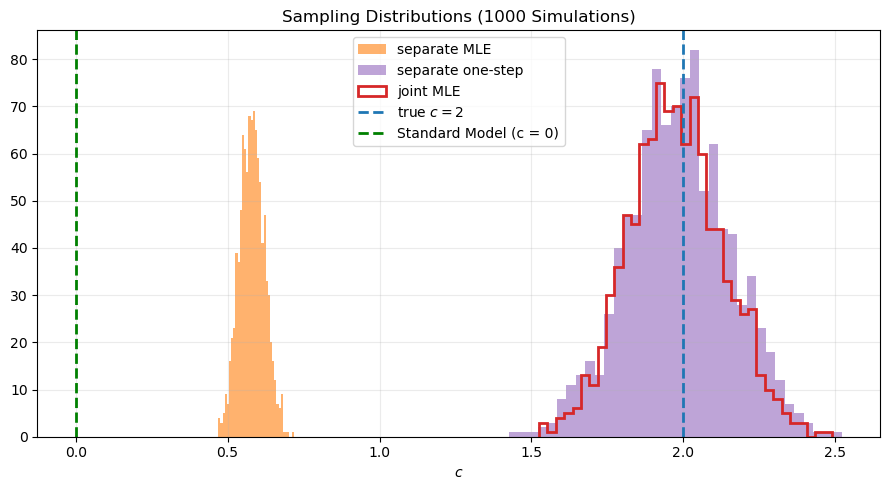

In [84]:
# Select any fitted (method, estimator) pairs to show in this histogram.
sampling_distribution_plot = [
    ("separate", "plug_in"),
    ("separate", "one_step"),
    ("joint", "plug_in")
]

if run_simulation:
    estimator_colors = {"plug_in": "C1", "one_step": "C4"}
    method_hist_styles = {
        "separate": dict(histtype="bar", alpha=0.6),
        "joint": dict(histtype="step", linewidth=2),
    }
    estimator_labels = {"plug_in": "MLE", "one_step": "one-step"}

    for method, estimator in sampling_distribution_plot:
        if method not in simulation_results:
            raise ValueError(
                f"Cannot plot {method!r}: it was not run. "
                f"Available methods are {tuple(simulation_results)}."
            )
        if estimator not in estimator_labels:
            raise ValueError(
                f"Unknown estimator {estimator!r}; use 'plug_in' or 'one_step'."
            )

    fig, ax = plt.subplots(figsize=(9, 5))
    for method, estimator in sampling_distribution_plot:
        result = simulation_results[method]
        valid_key = "valid_plugin" if estimator == "plug_in" else "valid_os"
        ax.hist(
            result[estimator][result[valid_key]], bins=35,
            color=(
                "C3" if method == "joint" and estimator == "plug_in"
                else estimator_colors[estimator]
            ),
                        
            label=f"{method} {estimator_labels[estimator]}",
            **method_hist_styles[method],
        )
    ax.axvline(c_true, color="C0", linestyle="--", linewidth=2, label=fr"true $c={c_true:g}$")
    ax.axvline(0, color="green", linestyle="--", linewidth=2, label=f"Standard Model (c = 0)")
    ax.set(xlabel="$c$", title=f"Sampling Distributions ({N_sim} Simulations)")#, information x{R})")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    if save_fig:
        output = f"../results/HERA/sampling_dist_c={c_true}_Lambda={int(Lambda)}.pdf"
        fig.savefig(output, 
            format="pdf", bbox_inches="tight")
        print("Figure saved at:", output)
    plt.show()

---
## 8. Coverage diagnostics

The following cells show CI strip plots, empirical coverage and interval widths, and the full coverage-calibration curve for the entries selected in `sampling_distribution_plot`. An MLE (`plug_in`) entry uses its bootstrap interval and therefore requires `compute_bootstrap_coverage=True`.

In [85]:
# Plotting-only choice: change this after running or loading the simulation.
simulation_joint_mle_ci_plot_methods = ("asymptotic",)
available_simulation_joint_ci_methods = (
    {"bootstrap", "asymptotic"}
    if simulation_joint_mle_ci_method == "both"
    else {simulation_joint_mle_ci_method}
)
if (not simulation_joint_mle_ci_plot_methods or
        not set(simulation_joint_mle_ci_plot_methods)
        <= available_simulation_joint_ci_methods):
    raise ValueError(
        "simulation_joint_mle_ci_plot_methods must be a nonempty subset "
        "of the joint-MLE CI methods that were computed."
    )

if run_simulation:
    coverage_plot_series = []
    for method, estimator in sampling_distribution_plot:
        result = simulation_results[method]
        if estimator == "one_step":
            estimates = result["one_step"]
            ses = result["one_step_se"]
            cis = result["ci_one_step"]
            label = f"{method} one-step"
        elif estimator == "plug_in":
            added_mle_series = False
            ci_methods_to_plot = (
                simulation_joint_mle_ci_plot_methods
                if method == "joint" else ("bootstrap",)
            )
            for ci_method in ci_methods_to_plot:
                cis = result[f"ci_mle_{ci_method}"]
                ses = result[f"mle_se_{ci_method}"]
                valid = (
                    np.isfinite(result["plug_in"]) & np.isfinite(ses)
                    & np.all(np.isfinite(cis), axis=1)
                )
                if not np.any(valid):
                    continue
                coverage_plot_series.append({
                    "method": method, "estimator": estimator,
                    "ci_method": ci_method,
                    "label": f"{method} MLE", #({ci_method})",
                    "estimates": result["plug_in"], "ses": ses,
                    "cis": cis, "valid": valid,
                })
                added_mle_series = True
            if not added_mle_series:
                print(f"Skipping {method} MLE: no confidence intervals computed.")
            continue
        else:
            raise ValueError(f"Unknown estimator {estimator!r}.")

        valid = (
            np.isfinite(estimates)
            & np.isfinite(ses)
            & np.all(np.isfinite(cis), axis=1)
        )
        coverage_plot_series.append({
            "method": method, "estimator": estimator,
            "ci_method": "one_step", "label": label,
            "estimates": estimates, "ses": ses, "cis": cis, "valid": valid,
        })

    if not coverage_plot_series:
        raise ValueError(
            "No selected estimator has confidence intervals available for coverage plots."
        )

In [ ]:
# Strip plot
if run_simulation:
    for series in coverage_plot_series:
        valid = series["valid"]
        cis = series["cis"]
        estimates = series["estimates"]
        covered = (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
        ci_indices = np.flatnonzero(valid)
        series_color = estimator_colors[series["estimator"]]

        fig, ax = plt.subplots(figsize=(8, max(5, len(ci_indices) / 15)))
        for row, idx in enumerate(ci_indices):
            linestyle = "-" if covered[idx] else ":"
            marker = "o" if covered[idx] else "x"
            alpha_i = 0.8 if covered[idx] else 0.45
            ax.plot(cis[idx], [row, row], color=series_color, ls=linestyle, lw=1, alpha=alpha_i)
            ax.plot(estimates[idx], row, marker, color=series_color, ms=2.5, alpha=alpha_i)
        ax.axvline(c_true, color="black", lw=2, ls="--")
        coverage_rate = covered[valid].mean()
        ax.legend(handles=[
            Line2D([0], [0], color=series_color, lw=2, ls="-", label="covers"),
            Line2D([0], [0], color=series_color, lw=2, ls=":", label="misses"),
            Line2D([0], [0], color="black", lw=2, ls="--", label=fr"true $c={c_true:g}$"),
        ])
        ax.set(
            xlabel="$c$", ylabel="valid simulation index",
            title=f"{series['label'].capitalize()} 95% CIs — coverage {coverage_rate:.3f}",
        )
        plt.tight_layout()
        if save_fig:
            fig.savefig(f"../results/HERA/strip_plot_c={c_true}_Lambda={Lambda}.pdf", 
                format="pdf", bbox_inches="tight")
        plt.show()

Figure saved at: ../results/HERA/coverage_width_c=2_Lambda=500.pdf


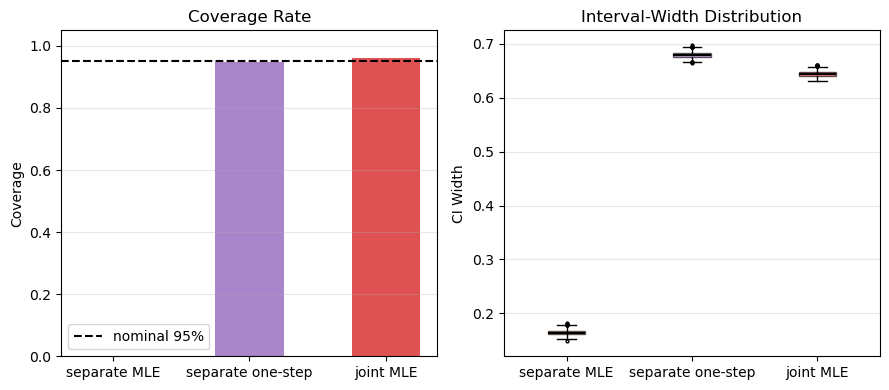

In [87]:
# Coverage rate & CI width
if run_simulation:
    estimator_colors = {"plug_in": "C1", "one_step": "C4"}
    method_hatches = {"separate": "", "joint": ""}
    labels = [series["label"] for series in coverage_plot_series]
    CI_arrays = [series["cis"][series["valid"]] for series in coverage_plot_series]
    colors = [
        "C3" if series["method"] == "joint" and series["estimator"] == "plug_in"
        else estimator_colors[series["estimator"]]
        for series in coverage_plot_series
    ]
    hatches = [method_hatches[series["method"]] for series in coverage_plot_series]

    coverages = [np.mean((ci[:, 0] <= c_true) & (ci[:, 1] >= c_true)) for ci in CI_arrays]
    widths = [ci[:, 1] - ci[:, 0] for ci in CI_arrays]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    bars = axes[0].bar(labels, coverages, color=colors, alpha=0.8, width=0.5)
    for bar, hatch in zip(bars, hatches):
        bar.set_hatch(hatch)
    axes[0].axhline(0.95, color="black", linestyle="--", label="nominal 95%")
    axes[0].set(ylabel="Coverage", title="Coverage Rate", ylim=(0, 1.05))
    axes[0].legend()
    bp = axes[1].boxplot(
        widths, tick_labels=labels, patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        flierprops=dict(marker='.', markersize=4, markeredgecolor="black"),
    )
    for box, color, hatch in zip(bp["boxes"], colors, hatches):
        box.set_facecolor(color)
        box.set_hatch(hatch)
        box.set_alpha(0.6)
    axes[1].set(ylabel="CI Width", title="Interval-Width Distribution")
    for ax in axes:
        ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    if save_fig:
        output = f"../results/HERA/coverage_width_c={c_true}_Lambda={int(Lambda)}.pdf"
        fig.savefig(output, 
            format="pdf", bbox_inches="tight")
        print("Figure saved at:", output)
    plt.show()

Figure saved at: ../results/HERA/coverage_calibration_c=2_Lambda=500.pdf


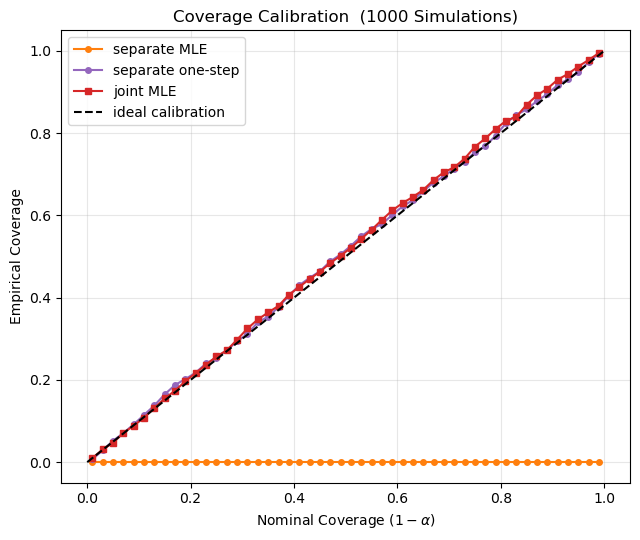

In [90]:
# Coverage calibration
if run_simulation:
    alphas = np.linspace(0.01, 0.99, 50)
    nominal_levels = 1.0 - alphas
    estimator_colors = {"plug_in": "C1", "one_step": "C4"}
    method_markers = {"separate": "o", "joint": "s"}
    fig, ax = plt.subplots(figsize=(6.5, 5.5))

    for series in coverage_plot_series:
        valid = series["valid"]
        estimates = series["estimates"][valid]
        ses = series["ses"][valid]
        empirical_coverage = []
        for alpha_i in alphas:
            z = norm.ppf(1.0 - alpha_i / 2.0)
            lo = estimates - z * ses
            hi = estimates + z * ses
            empirical_coverage.append(np.mean((lo <= c_true) & (hi >= c_true)))
        ax.plot(
            nominal_levels, empirical_coverage,
            color=(
                "C3" if series["method"] == "joint" and series["estimator"] == "plug_in"
                else estimator_colors[series["estimator"]]
            ),
            marker=method_markers[series["method"]],
            ms=4, label=series["label"],
        )
    ax.plot([0, 1], [0, 1], "k--", label="ideal calibration")
    ax.set(xlabel=r"Nominal Coverage $(1-\alpha)$", ylabel="Empirical Coverage", title=f'Coverage Calibration  ({N_sim} Simulations)')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    if save_fig:
        output = f"../results/HERA/coverage_calibration_c={c_true}_Lambda={int(Lambda)}.pdf"
        fig.savefig(output, 
            format="pdf", bbox_inches="tight")
        print("Figure saved at:", output)
    plt.show()

In [ ]:
save_simulation_results = True
simulation_output = (
    f"simulation_results/HERA/V_simulation_results_c={c_true}_Lambda={int(Lambda)}.npz"
)

if run_simulation and save_simulation_results:
    from pathlib import Path
    Path(simulation_output).parent.mkdir(parents=True, exist_ok=True)
    save_payload = dict(
        notebook_file="V_demo.ipynb",
        data_archive="Dataset/data_HERA_F3_aZ_PID200.npz",
        numpy_version=np.__version__, pdfset=pdfset,
        c_true=c_true, Lambda=Lambda, N_sim=N_sim, data_information_multiplier=R,
        simulation_seed=(-1 if simulation_seed is None else simulation_seed),
        n_boot_sim=n_boot_sim, c0=c0, loss_scale=simulation_loss_scale,
        spline_degree=degree, n_basis=M, parametrize=parametrize,
        enforce_sum_rule=enforce_sum_rule, nonnegative_pdf=nonnegative_pdf,
        pin_endpoints=pin_endpoints, sum_rule_total=sum_rule_total,
        joint_optimizer=simulation_joint_optimizer,
        separate_beta_optimizer=simulation_separate_beta_optimizer,
        separate_c_optimizer=simulation_separate_c_optimizer,
        c_range=np.asarray(simulation_c_range), bootstrap_ci_alpha=0.05,
        data_mode=data_mode, pseudo_seed=pseudo_seed,
        restrict_to_data_x_range=restrict_to_data_x_range,
        fitted_grid=grid, target_offset=target_offset,
        match_fixed_tails=match_fixed_tails,
        continuity_constraint=continuity_constraint,
        boundary_values=boundary_values, beta_fixed=beta_fixed,
        free_basis_indices=free_basis_indices,
        background_mode=background_mode, background_inside_eft=background_inside_eft,
        additive_background=additive_background, eft_background=eft_background,
        eft_offset=eft_fixed_offset, fitted_range_sum_rule=sum_rule_value,
        simulation_fit_method=simulation_fit_method,
        simulation_fit_methods=np.asarray(simulation_fit_methods),
        simulation_joint_mle_ci_method=simulation_joint_mle_ci_method,
        simulation_joint_mle_hessian_method=simulation_joint_mle_hessian_method,
        sampling_distribution_plot=np.asarray(sampling_distribution_plot),
        compute_bootstrap_coverage=compute_bootstrap_coverage,
        xQ2=xQ2, Sigma=Sigma, design_matrix=A,
        generating_mean=mu_eft_true, full_generating_mean=mu_pseudo,
        full_grid=grid_full,
        w_norm_present=(w_norm is not None),
        w_norm=(np.asarray(w_norm) if w_norm is not None else np.empty(0)),
        klin_values=_klin(xQ2[:, 1]), kquad_values=_kquad(xQ2[:, 1]),
    )
    for method, result in simulation_results.items():
        save_payload[f"{method}_plug_in_estimates"] = result["plug_in"]
        save_payload[f"{method}_one_step_estimates"] = result["one_step"]
        save_payload[f"{method}_CIs_one_step"] = result["ci_one_step"]
        save_payload[f"{method}_one_step_SEs"] = result["one_step_se"]
        save_payload[f"{method}_CIs_mle_asymptotic"] = result["ci_mle_asymptotic"]
        save_payload[f"{method}_mle_asymptotic_SEs"] = result["mle_se_asymptotic"]
        save_payload[f"{method}_CIs_mle_bootstrap"] = result["ci_mle_bootstrap"]
        save_payload[f"{method}_mle_bootstrap_SEs"] = result["mle_se_bootstrap"]
        if result["boot_samples"] is not None:
            save_payload[f"{method}_all_boot_samples"] = result["boot_samples"]
    np.savez(simulation_output, **save_payload)
    print(f"Saved {simulation_output}")

Saved simulation_results/HERA/V_simulation_results_c=2_Lambda=500_0902.npz


In [82]:
simulation_output = r"simulation_results/HERA/V_simulation_results_c=2_Lambda=500.npz"

with np.load(simulation_output) as saved:
    print("Saved variables:")
    print(saved.files)

    # Restore the names used directly by the plotting cells.
    c_true = saved["c_true"].item()
    Lambda = saved["Lambda"].item()
    N_sim = saved["N_sim"].item()
    R = saved["data_information_multiplier"].item()
    simulation_fit_method = saved["simulation_fit_method"].item()
    simulation_fit_methods = tuple(saved["simulation_fit_methods"].tolist())
    simulation_joint_mle_ci_method = (
        saved["simulation_joint_mle_ci_method"].item()
        if "simulation_joint_mle_ci_method" in saved.files else "bootstrap"
    )
    simulation_joint_mle_hessian_method = (
        saved["simulation_joint_mle_hessian_method"].item()
        if "simulation_joint_mle_hessian_method" in saved.files
        else "analytical"
    )
    compute_bootstrap_coverage = bool(saved["compute_bootstrap_coverage"].item())
    simulation_seed_saved = (
        saved["simulation_seed"].item() if "simulation_seed" in saved.files else -1
    )
    simulation_seed = None if simulation_seed_saved == -1 else int(simulation_seed_saved)
    n_boot_sim = saved["n_boot_sim"].item() if "n_boot_sim" in saved.files else 0
    sampling_distribution_plot = (
        [tuple(row) for row in saved["sampling_distribution_plot"].tolist()]
        if "sampling_distribution_plot" in saved.files
        else [(method, estimator) for method in simulation_fit_methods
              for estimator in ("plug_in", "one_step")]
    )

    # Keep all non-result entries in one self-describing configuration dictionary.
    result_suffixes = (
        "plug_in_estimates", "one_step_estimates", "CIs_one_step",
        "one_step_SEs", "CIs_mle", "mle_SEs",
        "CIs_mle_asymptotic", "mle_asymptotic_SEs",
        "CIs_mle_bootstrap", "mle_bootstrap_SEs", "all_boot_samples",
    )
    result_keys = {
        f"{method}_{suffix}"
        for method in simulation_fit_methods for suffix in result_suffixes
    }
    simulation_config = {}
    for key in saved.files:
        if key in result_keys:
            continue
        value = saved[key]
        simulation_config[key] = value.item() if value.ndim == 0 else value.copy()

    # Reconstruct the dictionary expected by the plotting cells.
    simulation_results = {}
    for method in simulation_fit_methods:
        result = {
            "plug_in": saved[f"{method}_plug_in_estimates"].copy(),
            "one_step": saved[f"{method}_one_step_estimates"].copy(),
            "ci_one_step": saved[f"{method}_CIs_one_step"].copy(),
            "one_step_se": saved[f"{method}_one_step_SEs"].copy(),
            "ci_mle_asymptotic": np.full((N_sim, 2), np.nan),
            "mle_se_asymptotic": np.full(N_sim, np.nan),
            "ci_mle_bootstrap": np.full((N_sim, 2), np.nan),
            "mle_se_bootstrap": np.full(N_sim, np.nan),
        }
        for ci_method in ("asymptotic", "bootstrap"):
            ci_key = f"{method}_CIs_mle_{ci_method}"
            se_key = f"{method}_mle_{ci_method}_SEs"
            if ci_key in saved.files:
                result[f"ci_mle_{ci_method}"] = saved[ci_key].copy()
            if se_key in saved.files:
                result[f"mle_se_{ci_method}"] = saved[se_key].copy()

        # Backward compatibility with files containing only one MLE CI array.
        legacy_ci_key = f"{method}_CIs_mle"
        legacy_se_key = f"{method}_mle_SEs"
        if legacy_ci_key in saved.files:
            legacy_method = ("asymptotic" if method == "joint" and
                             simulation_joint_mle_ci_method == "asymptotic"
                             else "bootstrap")
            result[f"ci_mle_{legacy_method}"] = saved[legacy_ci_key].copy()
            if legacy_se_key in saved.files:
                result[f"mle_se_{legacy_method}"] = saved[legacy_se_key].copy()

        boot_key = f"{method}_all_boot_samples"
        result["boot_samples"] = (
            saved[boot_key].copy() if boot_key in saved.files else None
        )
        if (result["boot_samples"] is not None and
                not np.any(np.isfinite(result["mle_se_bootstrap"]))):
            result["mle_se_bootstrap"] = np.nanstd(
                result["boot_samples"], axis=1, ddof=1
            )

        # Restore masks and coverage flags created by the simulation cell.
        result["valid_plugin"] = np.isfinite(result["plug_in"])
        result["valid_os"] = np.isfinite(result["one_step"])
        result["covered_one_step"] = (
            (result["ci_one_step"][:, 0] <= c_true)
            & (result["ci_one_step"][:, 1] >= c_true)
        )
        for ci_method in ("asymptotic", "bootstrap"):
            cis = result[f"ci_mle_{ci_method}"]
            ses = result[f"mle_se_{ci_method}"]
            result[f"covered_mle_{ci_method}"] = (
                (cis[:, 0] <= c_true) & (cis[:, 1] >= c_true)
            )
            result[f"valid_mle_ci_{ci_method}"] = (
                np.isfinite(result["plug_in"]) & np.isfinite(ses)
                & np.all(np.isfinite(cis), axis=1)
            )
        if result["boot_samples"] is not None:
            result["valid_boot"] = np.all(
                np.isfinite(result["ci_mle_bootstrap"]), axis=1
            )

        simulation_results[method] = result

run_simulation = True
print(
    f"Loaded {N_sim} simulations for {simulation_fit_methods}; "
    f"c_true={c_true:g}, Lambda={Lambda:g}, information x{R}."
)
print("\nSaved simulation configuration:")
for key in sorted(simulation_config):
    value = simulation_config[key]
    if isinstance(value, np.ndarray):
        print(f"  {key}: array shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"  {key}: {value!r}")

Saved variables:
['notebook_file', 'data_archive', 'numpy_version', 'pdfset', 'c_true', 'Lambda', 'N_sim', 'data_information_multiplier', 'simulation_seed', 'n_boot_sim', 'c0', 'loss_scale', 'spline_degree', 'n_basis', 'parametrize', 'enforce_sum_rule', 'nonnegative_pdf', 'pin_endpoints', 'sum_rule_total', 'joint_optimizer', 'separate_beta_optimizer', 'separate_c_optimizer', 'c_range', 'bootstrap_ci_alpha', 'data_mode', 'pseudo_seed', 'restrict_to_data_x_range', 'fitted_grid', 'target_offset', 'match_fixed_tails', 'continuity_constraint', 'boundary_values', 'beta_fixed', 'free_basis_indices', 'background_mode', 'background_inside_eft', 'additive_background', 'eft_background', 'eft_offset', 'fitted_range_sum_rule', 'simulation_fit_method', 'simulation_fit_methods', 'simulation_joint_mle_ci_method', 'sampling_distribution_plot', 'compute_bootstrap_coverage', 'xQ2', 'Sigma', 'design_matrix', 'generating_mean', 'full_generating_mean', 'full_grid', 'w_norm_present', 'w_norm', 'klin_values',